In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.8

# Интервальная оценка случайной величины



В контексте случайной величины можем определить интервальную оценку как пару предельных *(лимитных)* значений $T_1$ и&nbsp;$T_2$, таких, что:

$$\mathbb{P}(T_1 \leq X \leq T_2) \geq \gamma.$$

Обычно выбирают значение $\gamma$,  равное  $90\%$,  $95\%$  или $99\%$.

В контексте случайной величины (а не точечной оценки) данными границами являются *квантильные значения выборки*.

Рассмотрим пример с клиентскими платежами.

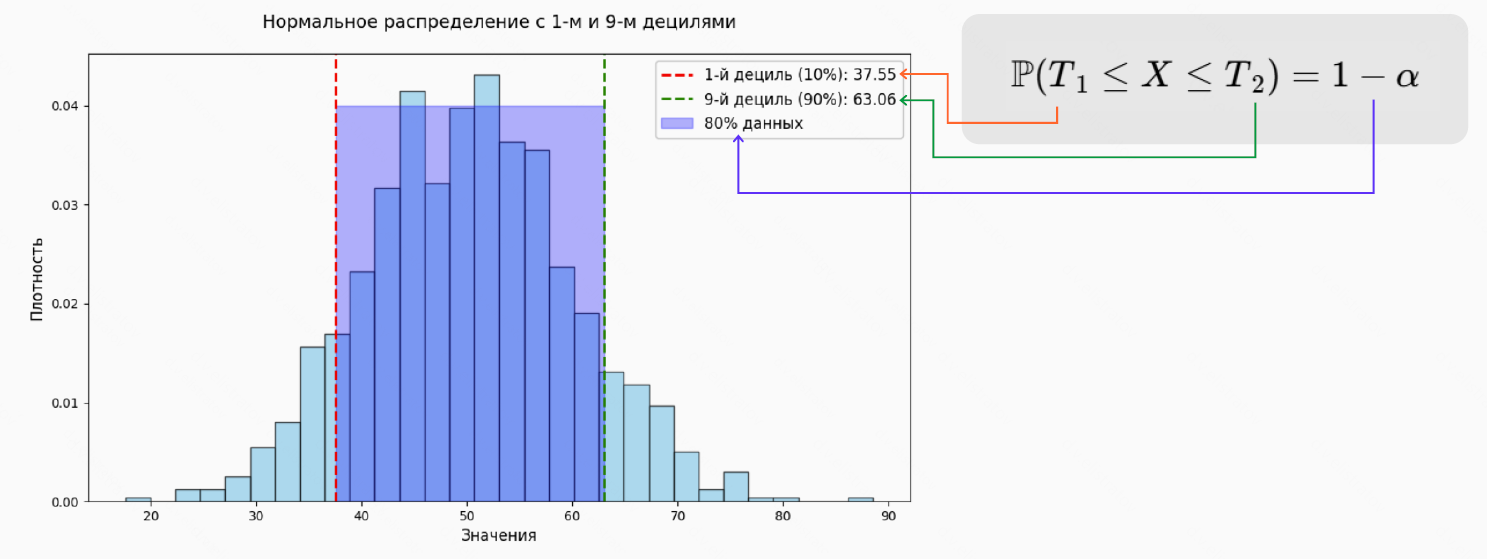

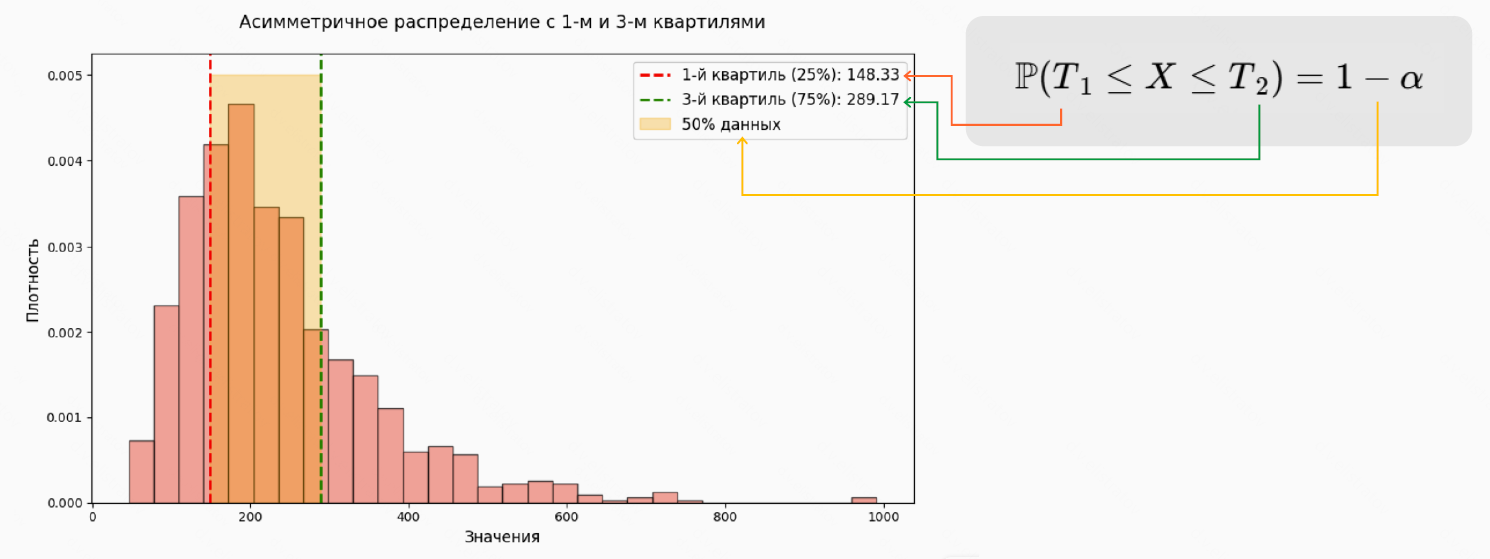

Рассмотрим пример логнормального распределения.

In [ ]:
payments = rng.lognormal(mean=5.5, sigma=0.8, size=2000)
print(f"чеков: {payments.size}, средний чек: {payments.mean():.0f} руб")

чеков: 2000, средний чек: 322 руб


Границы интервала, в который попадает $80\%$ чеков, — это $10$-й и $90$-й
перцентили выборки.

In [ ]:
low, high = np.percentile(payments, [10, 90])
print(f"80% чеков лежат между {low:.0f} и {high:.0f} руб")

80% чеков лежат между 82 и 653 руб


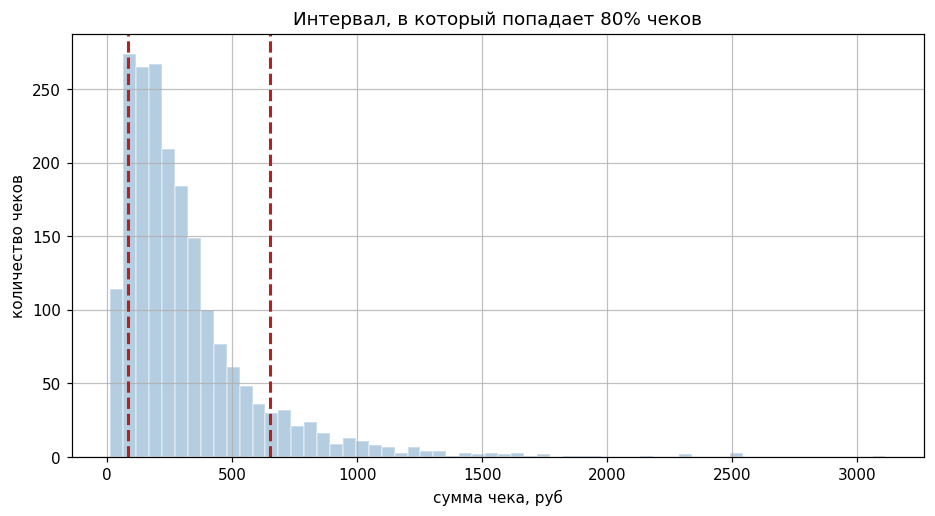

In [ ]:
plt.hist(payments, bins=60, color="steelblue", edgecolor="white", alpha=.4)
plt.axvline(low, color="firebrick", linestyle="--", lw=2)
plt.axvline(high, color="firebrick", linestyle="--", lw=2)
plt.title("Интервал, в который попадает 80% чеков")
plt.xlabel("сумма чека, руб")
plt.ylabel("количество чеков")
plt.show()

**Вопрос**

Границы для $50\%$ чеков — это какие перцентили? Посчитаем их и сравним ширину с интервалом для $80\%$.

In [ ]:
q25, q75 = np.percentile(payments, [25, 75])
print(f"50% чеков: от {q25:.0f} до {q75:.0f} руб, ширина {q75 - q25:.0f}")
print(f"80% чеков: от {low:.0f} до {high:.0f} руб, ширина {high - low:.0f}")

50% чеков: от 138 до 395 руб, ширина 258
80% чеков: от 82 до 653 руб, ширина 571


**Вывод**

Чем меньше доля данных, которую мы хотим
накрыть, тем уже интервал.

# Доверительный интервал для среднего



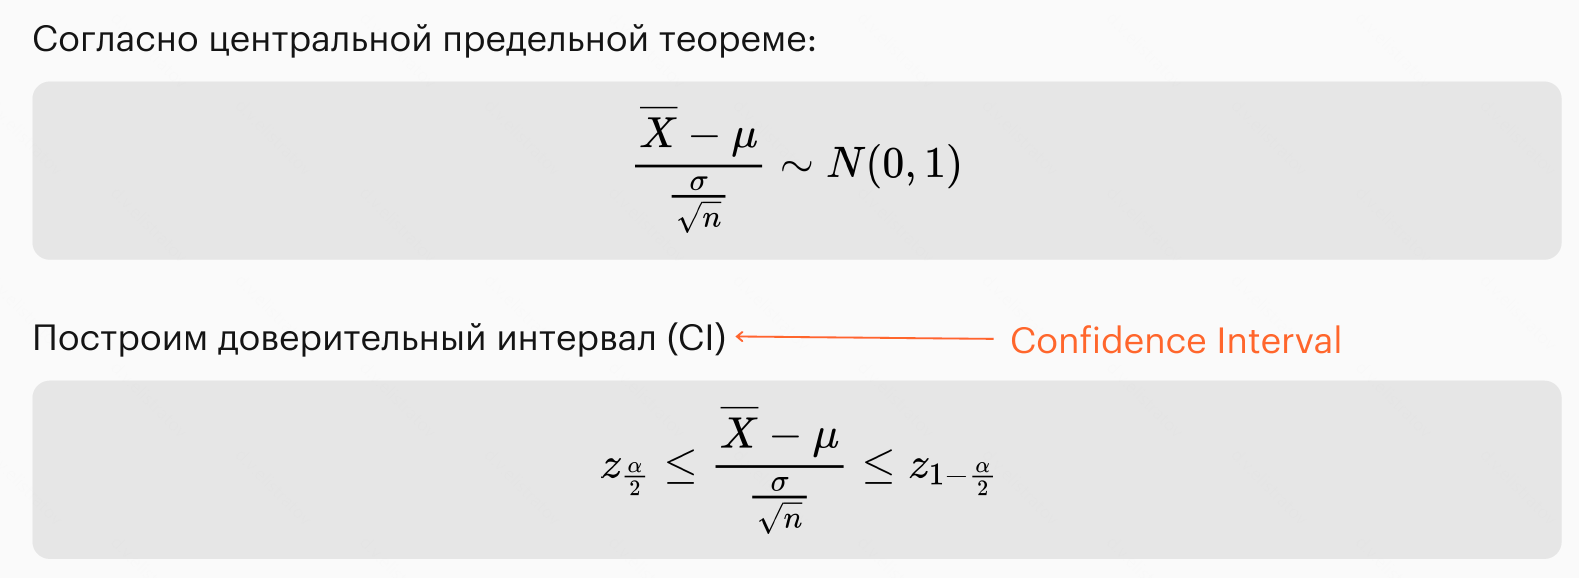

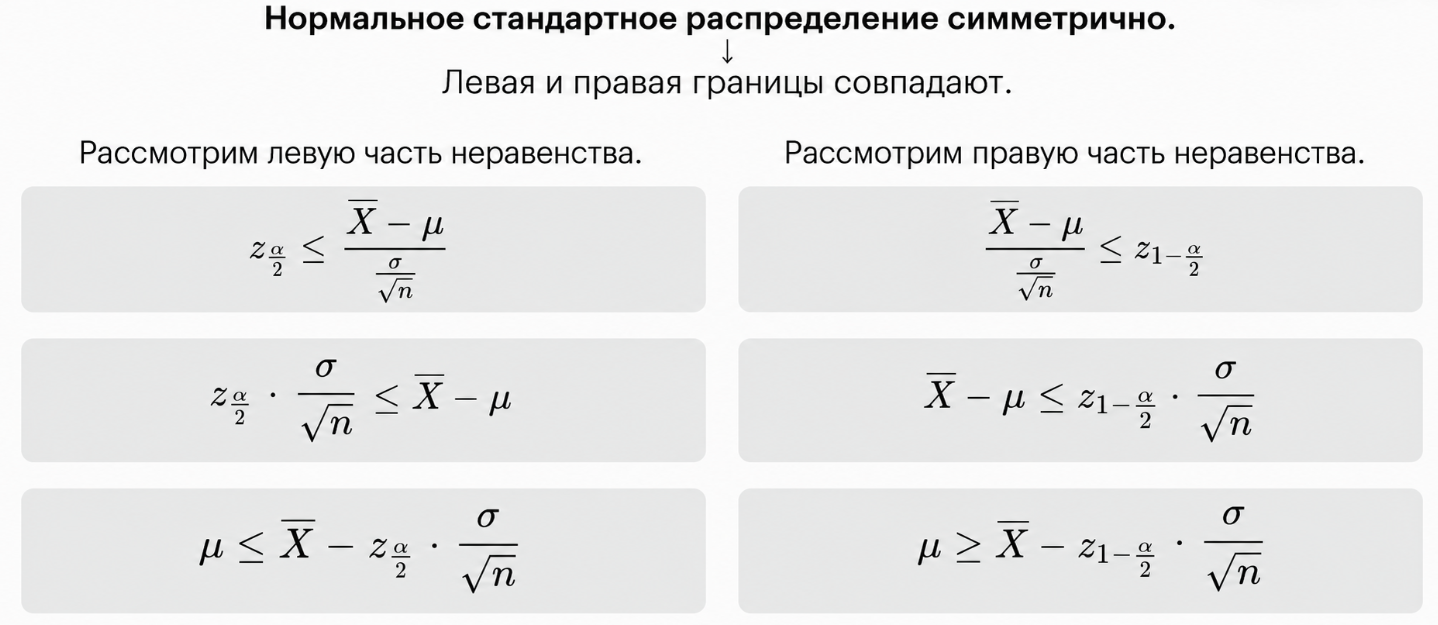

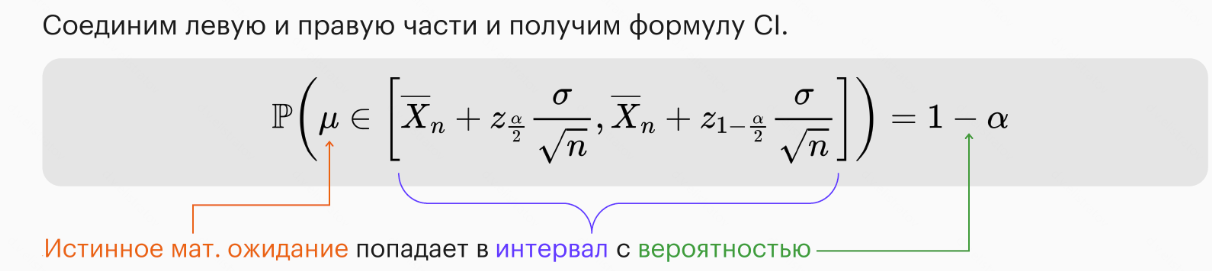

**Границы доверительного интервала для среднего рассчитываются по формуле**

$$
CI = \bar{x} \pm z_{\alpha/2} \cdot \frac{\sigma}{\sqrt{n}}.
$$

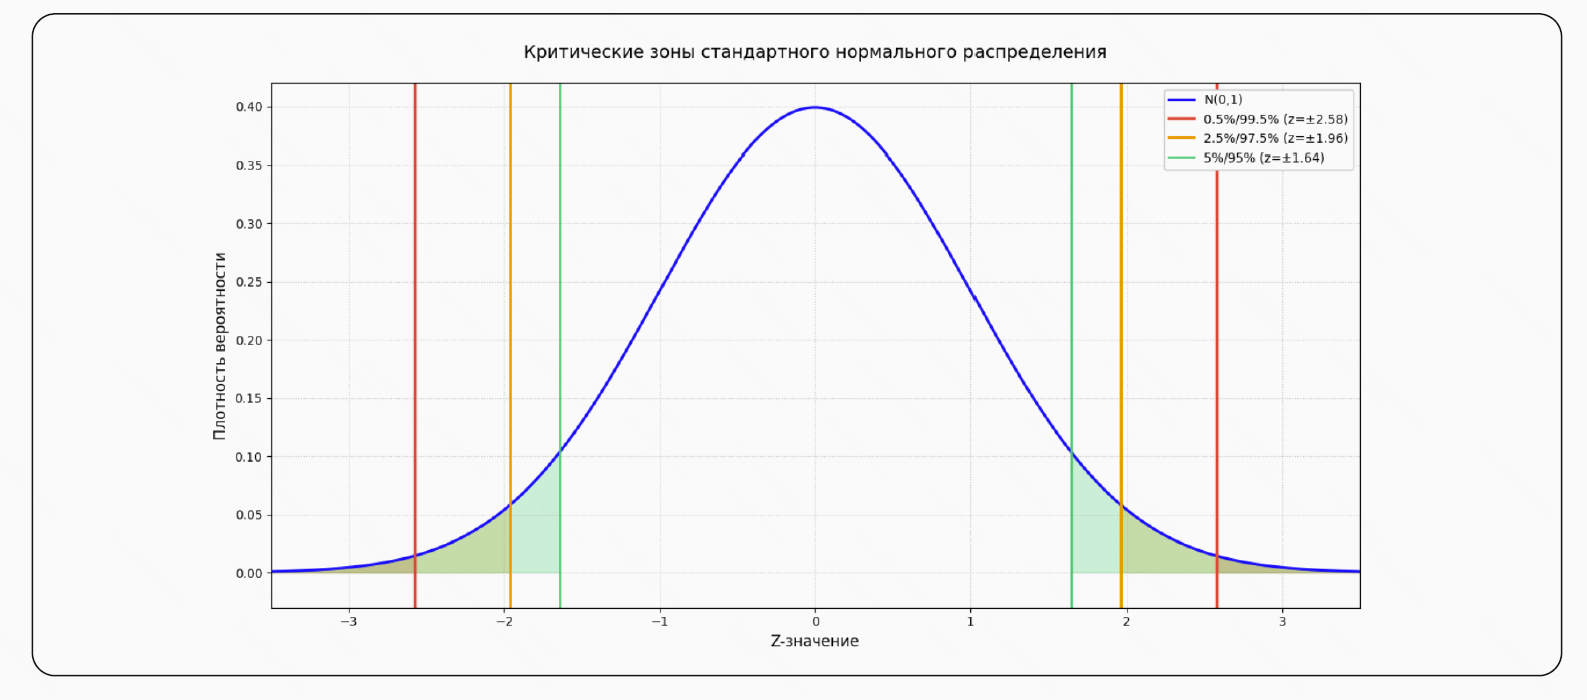

Истинное среднее $\mu$ фиксировано, а границы зависят от случайной выборки. Если много
раз повторить всю процедуру, доля интервалов, накрывших $\mu$, будет близка к $1-\alpha$.

| Уровень доверия | $z_{1-\alpha/2}$ |
|---:|---:|
| $90\%$ | $1.645$ |
| $95\%$ | $1.960$ |
| $99\%$ | $2.576$ |

Чем выше уровень доверия, тем дальше от нуля расположен квантиль и тем шире
интервал при той же выборке.

## Пример. Распределение чеков и доверительный интервал

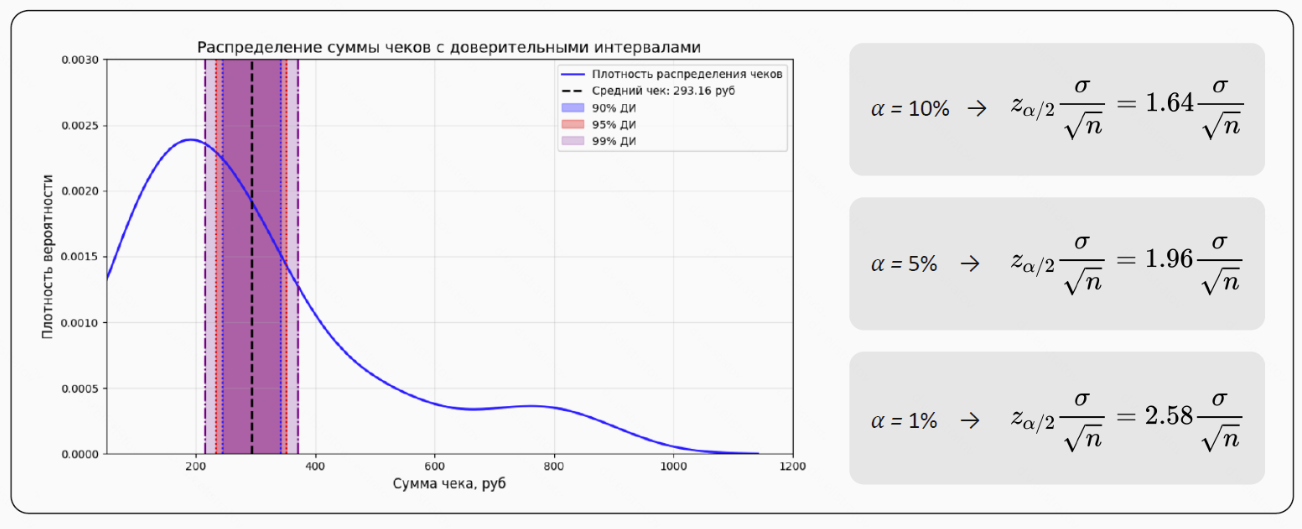

## Соберём алгоритм

In [ ]:
onboarding = rng.normal(loc=210, scale=60, size=120)
n = onboarding.size
print(f"пользователей: {n}")

пользователей: 120


**Первый шаг**

Точечная оценка и разброс выборки. У стандартного отклонения
берём `ddof=1`: делим на $n - 1$, а не на $n$.

In [ ]:
mean = onboarding.mean()
s = onboarding.std(ddof=1)
print(f"среднее: {mean:.1f} сек, стандартное отклонение: {s:.1f} сек")

среднее: 208.9 сек, стандартное отклонение: 56.1 сек


**Второй шаг**

Стандартная ошибка среднего $s / \sqrt{n}$. Она описывает
разброс оценки: как менялось бы выборочное среднее при повторном сборе данных.

In [ ]:
se = s / np.sqrt(n)
print(f"стандартная ошибка среднего: {se:.2f} сек")

стандартная ошибка среднего: 5.12 сек


**Третий шаг**

Множитель под уровень доверия $95\%$. В хвостах остаётся по
$2.5\%$, поэтому берём квантиль уровня $0.975$.

In [ ]:
from scipy.stats import norm
z = norm.ppf(0.975)
print(f"z = {z:.3f}")

z = 1.960


**Четвёртый шаг**

Собираем границы.

In [ ]:
left = mean - z * se
right = mean + z * se
print(f"95% доверительный интервал: [{left:.1f}, {right:.1f}] сек")

95% доверительный интервал: [198.9, 219.0] сек


**Вопрос**

Допустим, мы хотим повысить уровень доверия и строим $99\%$-ный интервал.

Как изменится интервал при увеличении уровня доверия?

In [ ]:
z99 = norm.ppf(0.995)
print(z99)

2.5758293035489004


In [ ]:
left99 = mean - z99 * se
right99 = mean + z99 * se
print(f"99% интервал: [{left99:.1f}, {right99:.1f}], ширина {right99 - left99:.1f}")
print(f"95% интервал: [{left:.1f}, {right:.1f}], ширина {right - left:.1f}")

99% интервал: [195.7, 222.1], ширина 26.4
95% интервал: [198.9, 219.0], ширина 20.1


**Ответ.**

$99\%$-ный интервал шире из-за большего квантиля.

## Зависимость ширины от размера выборки

В знаменателе стоит $\sqrt{n}$, а не $n$.

Значит, чтобы сузить интервал вдвое, данных нужно вчетверо больше. Это важно для A/B тестов.

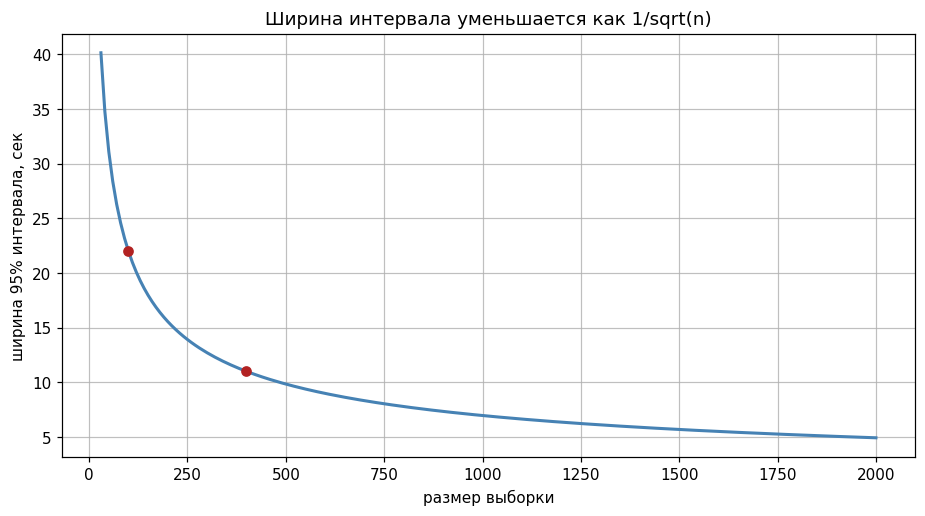

In [ ]:
sizes = np.arange(30, 2001, 10)
widths = 2 * z * s / np.sqrt(sizes)
plt.plot(sizes, widths, color="steelblue", lw=2)
plt.scatter([100, 400], [2 * z * s / 10, 2 * z * s / 20], color="firebrick", zorder=3)
plt.title("Ширина интервала уменьшается как 1/sqrt(n)")
plt.xlabel("размер выборки")
plt.ylabel("ширина 95% интервала, сек")
plt.show()

## Интерпретация результата?

Это **не** вероятность того, что истинное среднее лежит в уже построенном интервале, ведь в уже построенном интервале $\mu$ или попало или не попало в доверительный интервал.

$95\%$ - свойство процедуры: в длинной серии повторов примерно $95\%$ интервалов накроют истинное значение.

Проверим это симуляцией.

In [ ]:
true_mean = 210.0
lefts, rights = [], []
for _ in range(100):
    sample = rng.normal(true_mean, 60, 120)
    half = norm.ppf(0.975) * sample.std(ddof=1) / np.sqrt(sample.size)
    lefts.append(sample.mean() - half)
    rights.append(sample.mean() + half)

In [ ]:
lefts = np.array(lefts)
rights = np.array(rights)
covered = (lefts <= true_mean) & (true_mean <= rights)
print(f"накрыли истинное среднее: {covered.sum()} интервалов из 100")

накрыли истинное среднее: 91 интервалов из 100


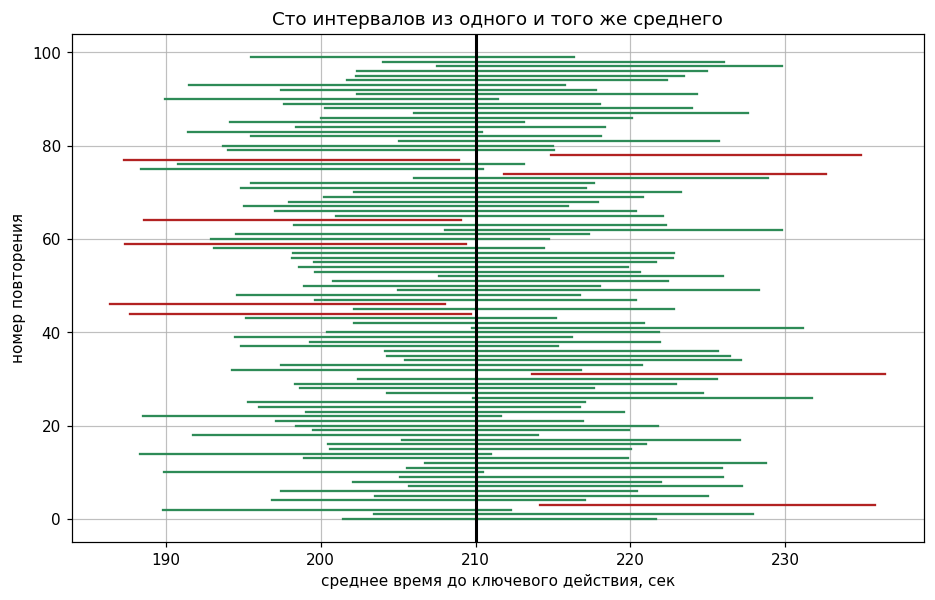

In [ ]:
plt.figure(figsize=(10, 6))
for i in range(100):
    color = "seagreen" if covered[i] else "firebrick"
    plt.plot([lefts[i], rights[i]], [i, i], color=color, lw=1.5)
plt.axvline(true_mean, color="black", lw=2)
plt.title("Сто интервалов из одного и того же среднего")
plt.xlabel("среднее время до ключевого действия, сек")
plt.ylabel("номер повторения")
plt.show()

Красные отрезки — промахи.

По сотне повторений их доля скачет: сто прогонов для оценки процента — сама по себе маленькая выборка.

Прогоним процедуру $5000$ раз и посмотрим, к чему сходится доля попаданий.

In [ ]:
hits = 0
for _ in range(5000):
    sample = rng.normal(true_mean, 60, 120)
    half = norm.ppf(0.975) * sample.std(ddof=1) / np.sqrt(sample.size)
    hits += abs(sample.mean() - true_mean) <= half
print(f"доля интервалов, накрывших истинное среднее: {hits / 5000:.3f}")

доля интервалов, накрывших истинное среднее: 0.952


На длинной серии доля попаданий приближается к выбранному уровню доверия.
Это свойство процедуры построения интервала, а не одного конкретного
результата.

# Доверительный интервал для доли

Простейшую вариацию доверительного интервала для доли называют **доверительным интервалом Вальда**.

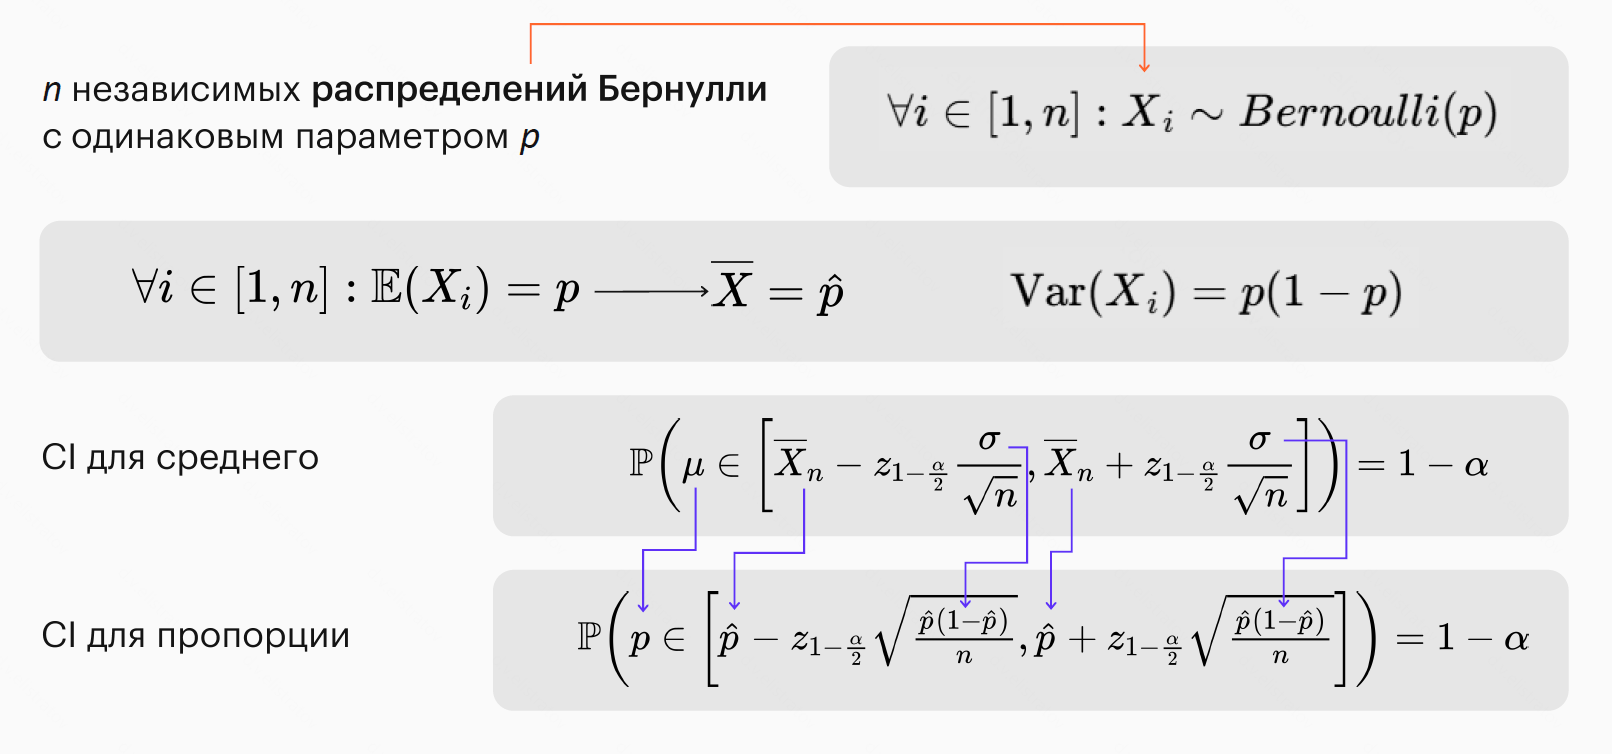

$$
CI = \hat{p} \pm z_{\alpha/2} \cdot \sqrt{\frac{\hat{p}(1-\hat{p})}{n}},
$$

где $\hat{p}$ — выборочная доля положительных ответов, $z_{\alpha/2}$ — критическое значение стандартного нормального распределения, $n$ — размер выборки.

## Пример. Конверсия лендинга

Посчитаем на конверсии лендинга: из тысячи визитов сто тридцать закончились
покупкой.

In [ ]:
visits, purchases = 1000, 130
p_hat = purchases / visits
print(f"конверсия: {p_hat:.1%}")

конверсия: 13.0%


Рассчитаем стандартное отклонение среднего.

In [ ]:
se_p = np.sqrt(p_hat * (1 - p_hat) / visits)

Рассчитаем границы доверительных интервалов.

In [ ]:
left_p = p_hat - z * se_p
right_p = p_hat + z * se_p
print(f"95% интервал: [{left_p:.1%}, {right_p:.1%}]")

95% интервал: [10.9%, 15.1%]



# Доверительный интервал для разности средних

Самый частый рабочий вопрос — не «чему равна метрика», а «отличается ли она
в двух группах». Интервалы позволяют ответить и на него.

Отдельные интервалы описывают оценку в каждой группе, но их пересечение не проверяет разницу. Для сравнения нужен один интервал самой разницы. Даже при пересечении интервалов групп разница может быть статистически различимой.

$$
CI_{diff} = (\bar{x}_A - \bar{x}_B) \pm z_{\alpha/2} \cdot \sqrt{\frac{s_A^2}{n_A} + \frac{s_B^2}{n_B}}
$$


## Доверительный интервал для разности двух средних

Пусть есть две независимые выборки $X_1,\ldots,X_{n_A}$ и $Y_1,\ldots,Y_{n_B}$.

Нас интересует разность средних $\mu_A-\mu_B.$

Для выборочных средних:

$$
\overline X_A \approx
\mathcal N\left(
\mu_A,\frac{\sigma_A^2}{n_A}
\right),
$$

$$
\overline X_B \approx
\mathcal N\left(
\mu_B,\frac{\sigma_B^2}{n_B}
\right).
$$

Так как выборки независимы,

$$
\overline X_A-\overline X_B
\approx
\mathcal N\left(
\mu_A-\mu_B,
\frac{\sigma_A^2}{n_A}
+
\frac{\sigma_B^2}{n_B}
\right).
$$

Поэтому стандартная ошибка разности средних равна

$$
SE=
\sqrt{
\frac{\sigma_A^2}{n_A}
+
\frac{\sigma_B^2}{n_B}
}.
$$

Получаем доверительный интервал:

$$
(\overline X_A-\overline X_B)
\pm
z_{1-\alpha/2}
\sqrt{\frac{\sigma_A^2}{n_A}+\frac{\sigma_B^2}{n_B}}
$$

## Варианты развития событий

Рассмотрим все варианты развития событий с точки зрения вхождения нуля в доверительный интервал разницы, а также с точки зрения пересечения доверительных интервалов самих групп.

### Кейс 1.1. Среднее непрерывной величины. Пересекаются и входит

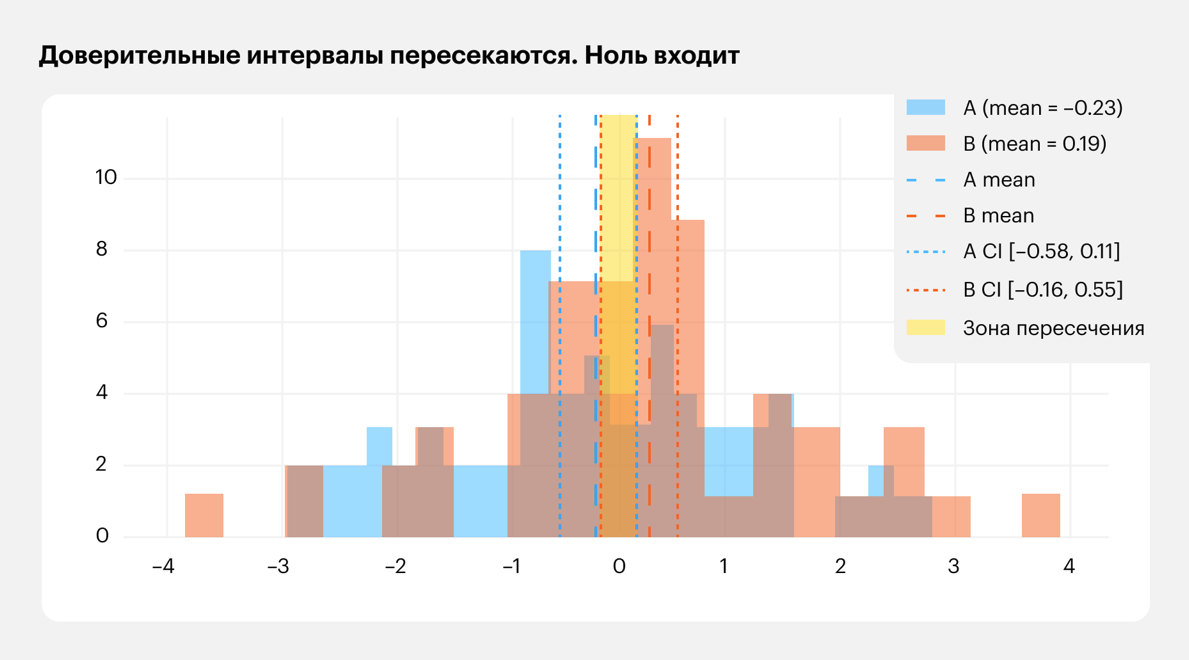

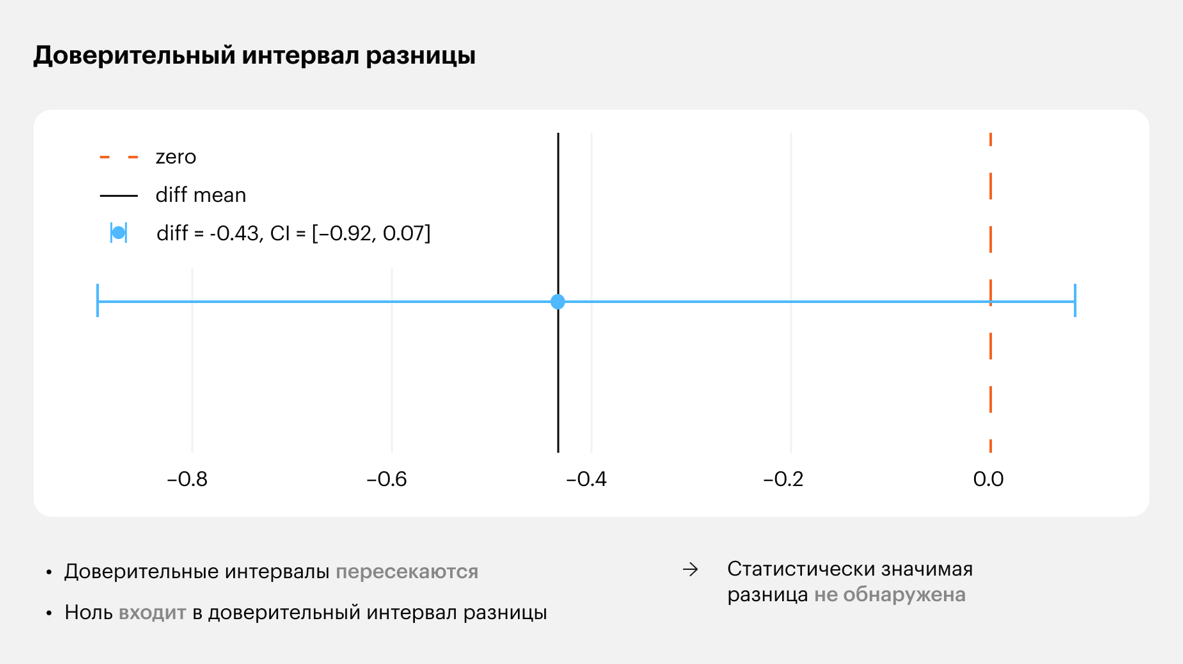

### Кейс 1.2. Среднее непрерывной величины. Пересекаются и не входит

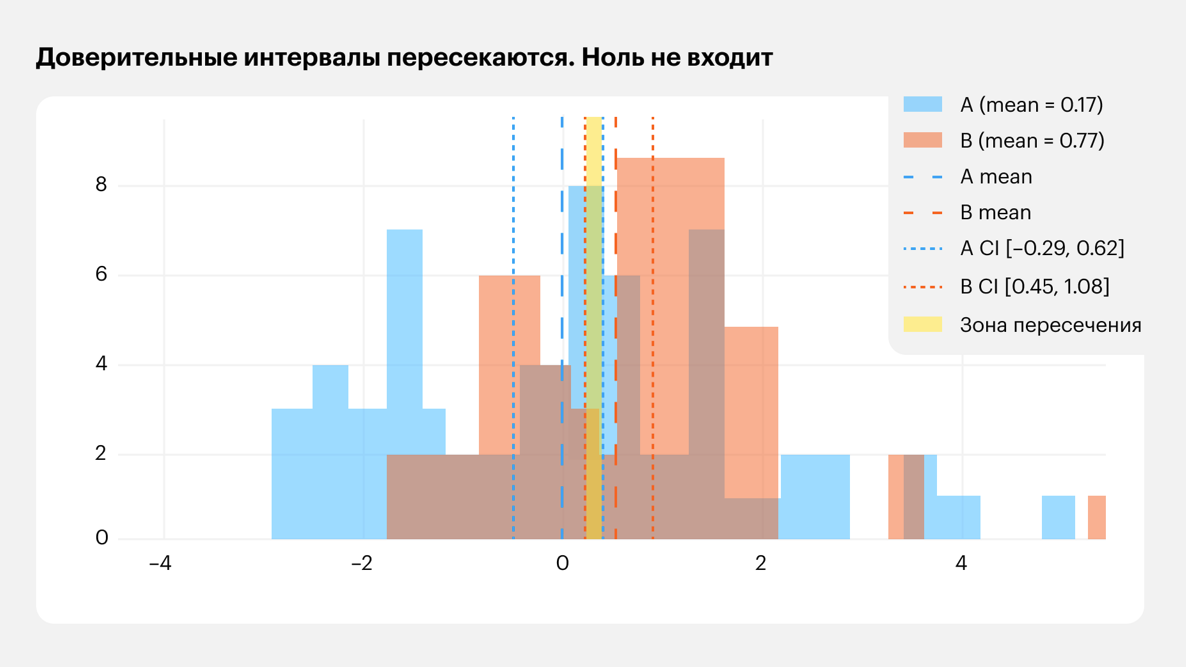

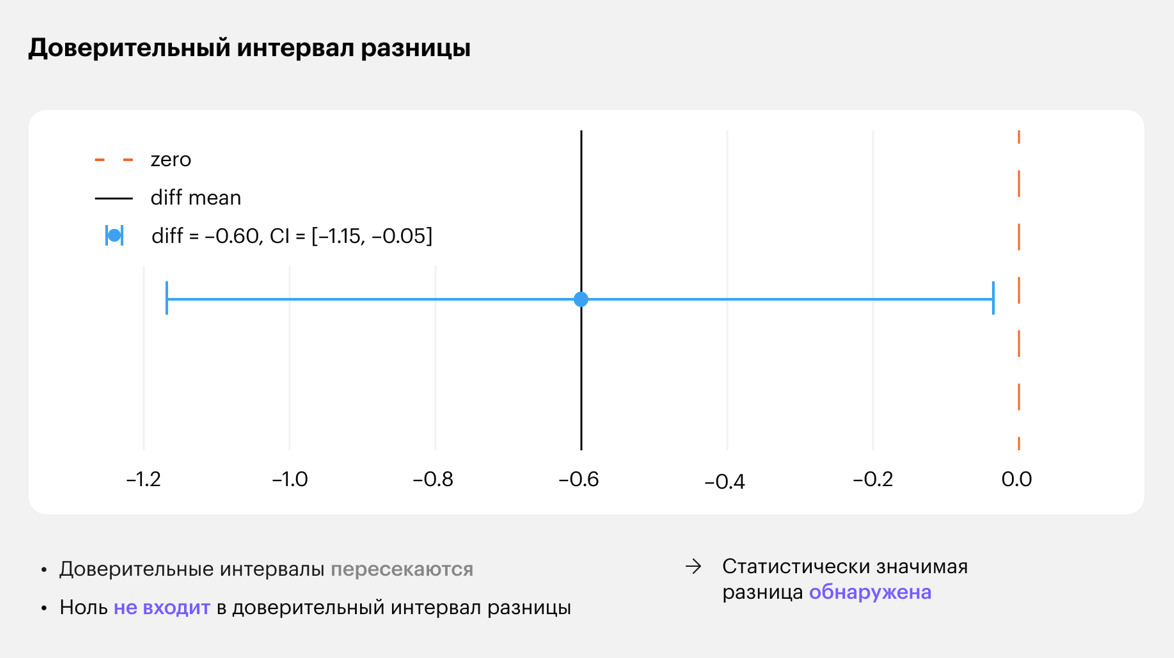

### Кейс 1.3. Среднее непрерывной величины. Не пересекаются и не входит

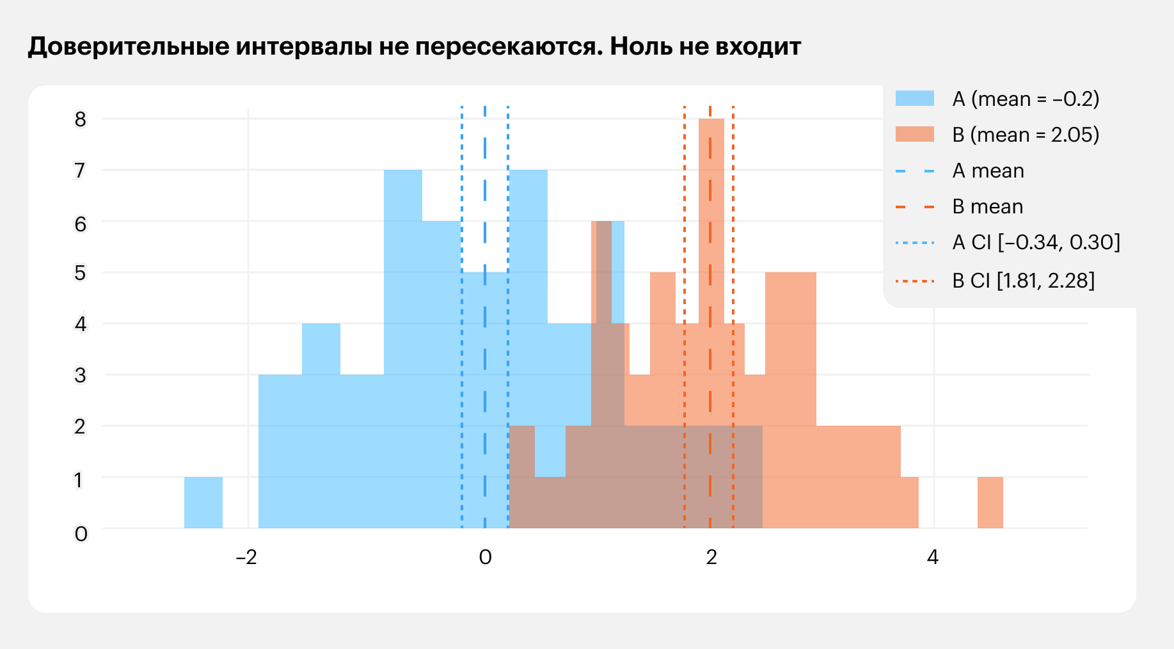

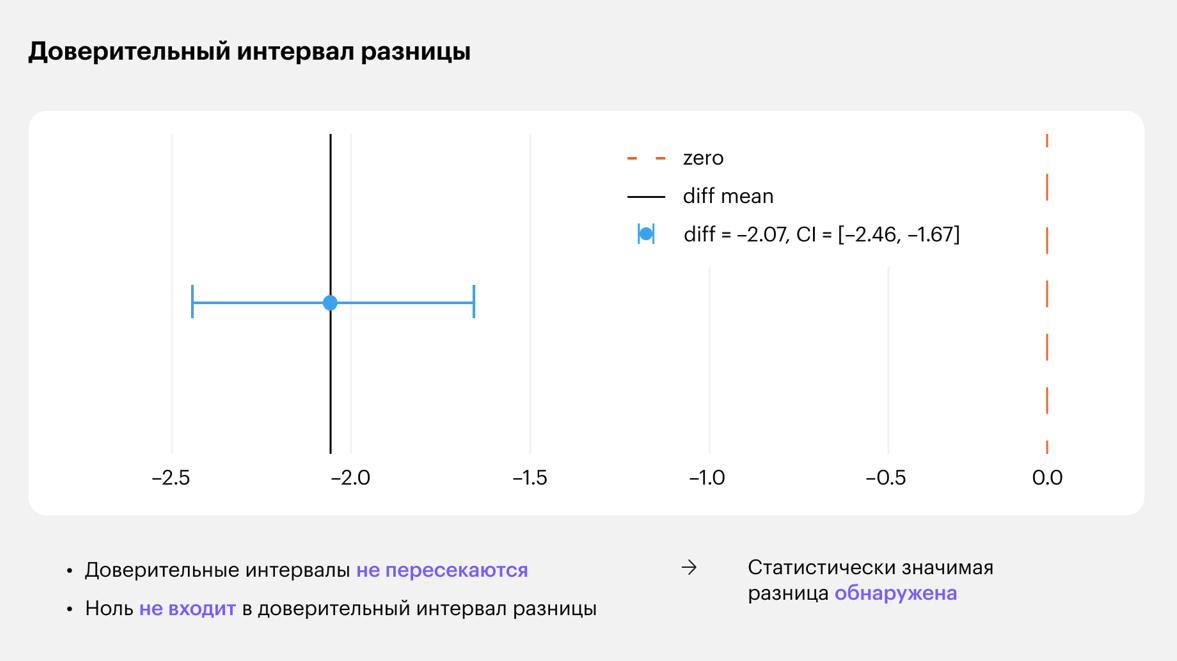

### Кейс 2.1. Конверсии. Пересекаются и входит

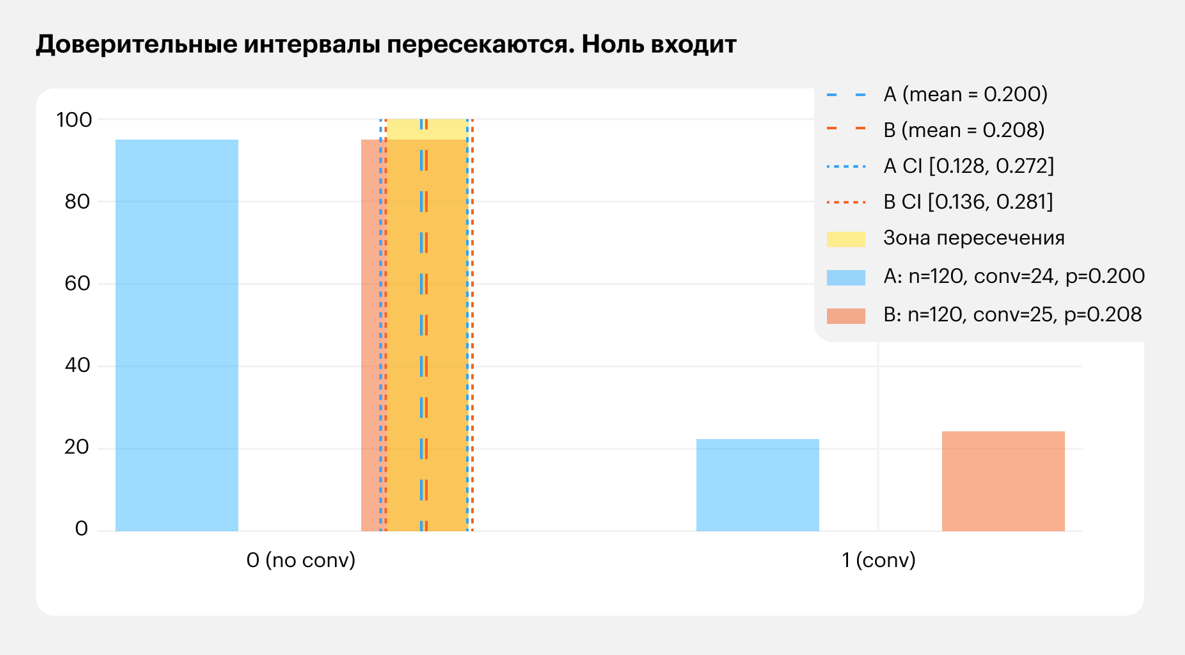

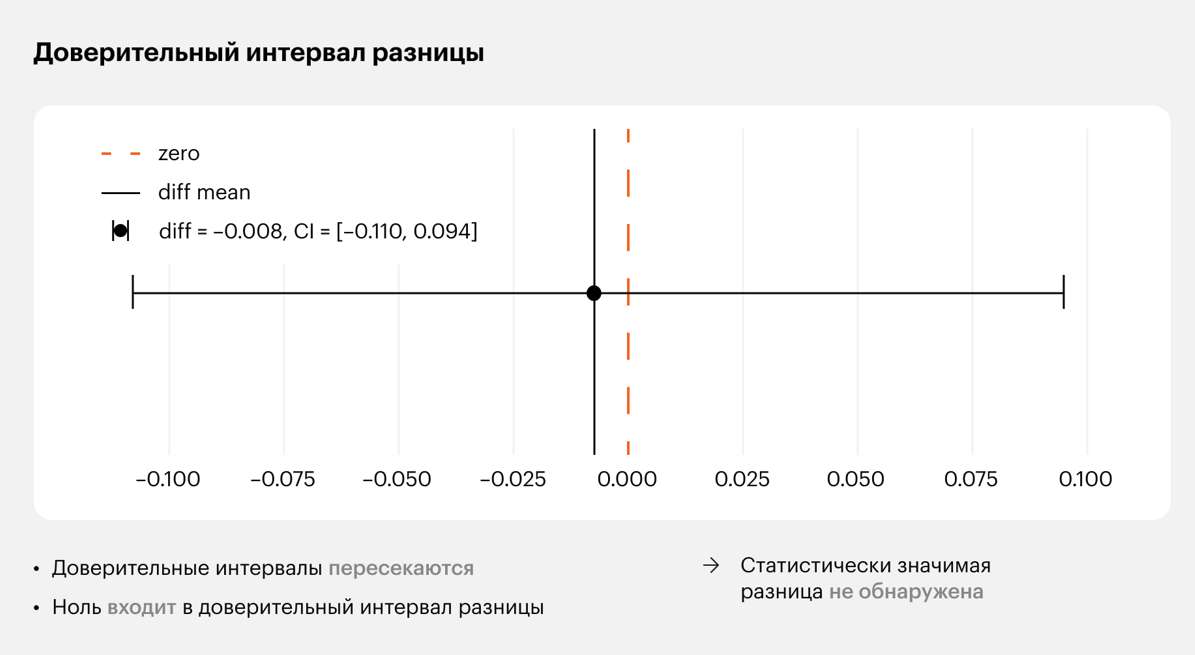

### Кейс 2.2. Конверсии. Пересекаются и не входит

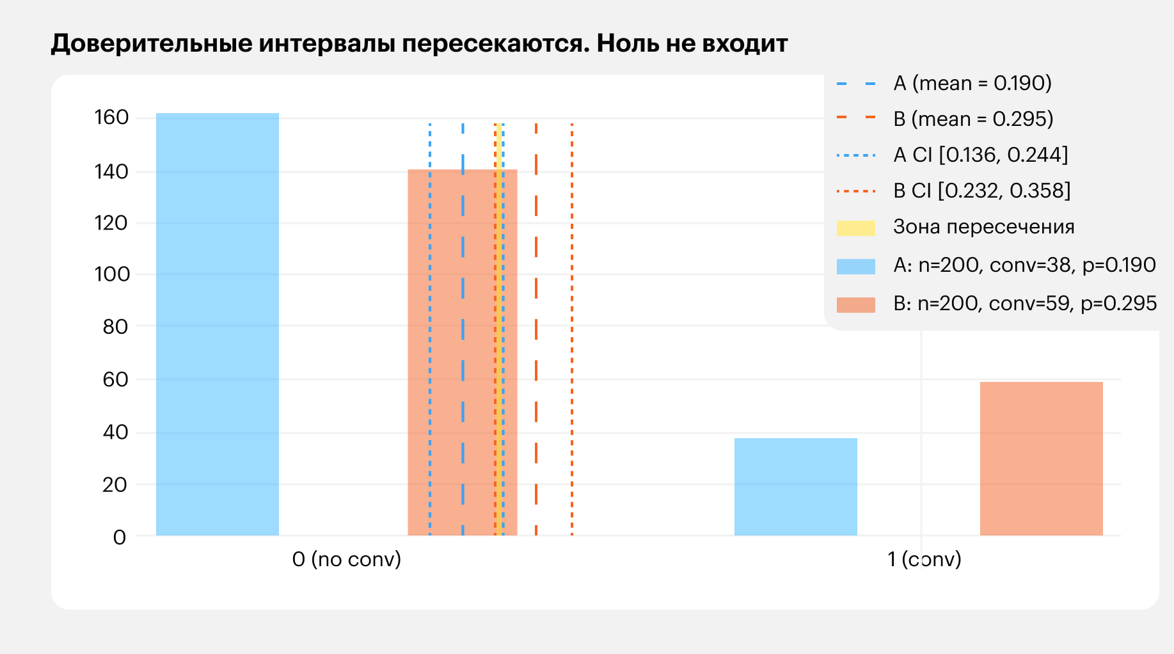

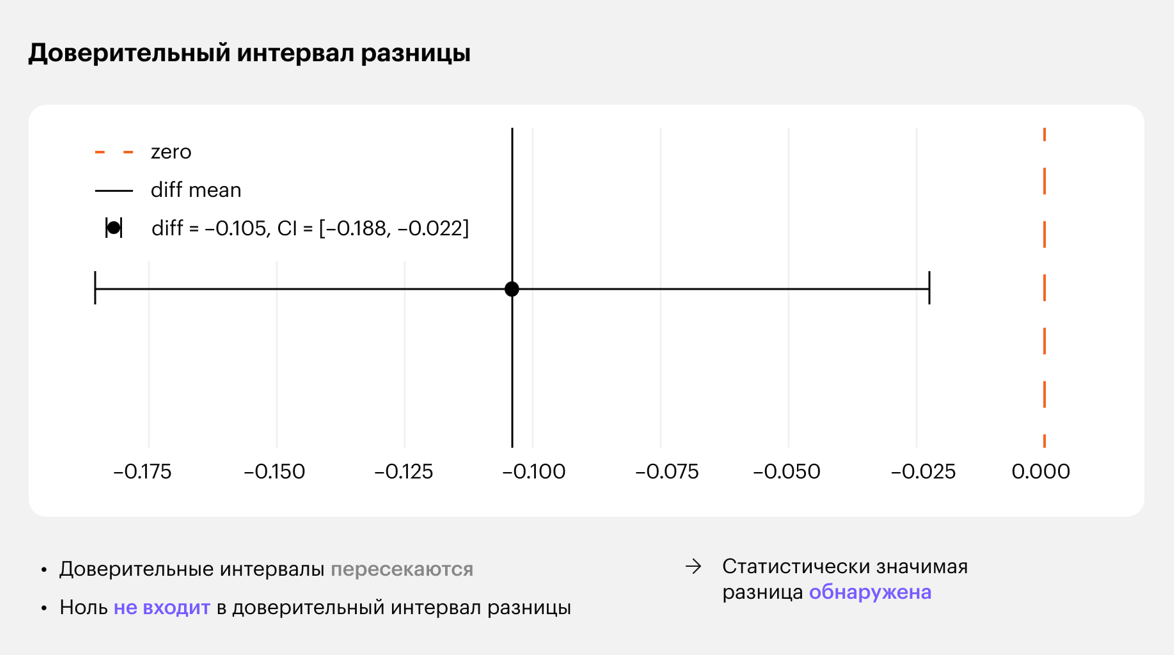

### Кейс 2.3. Конверсии. Не пересекаются и не входит

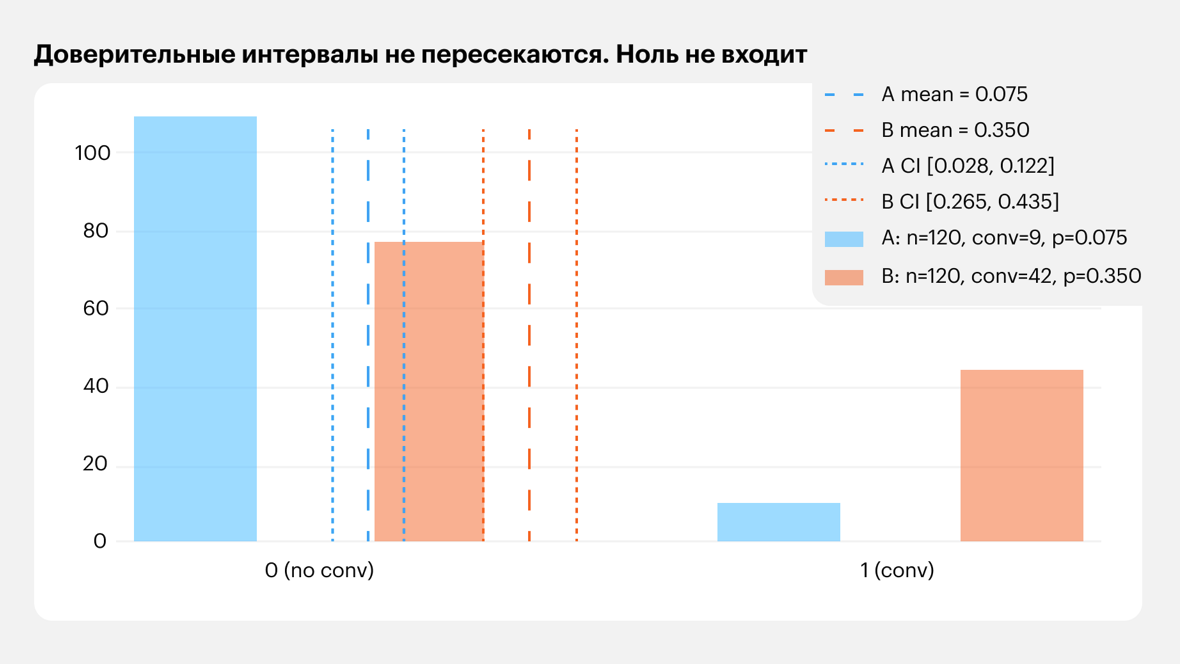

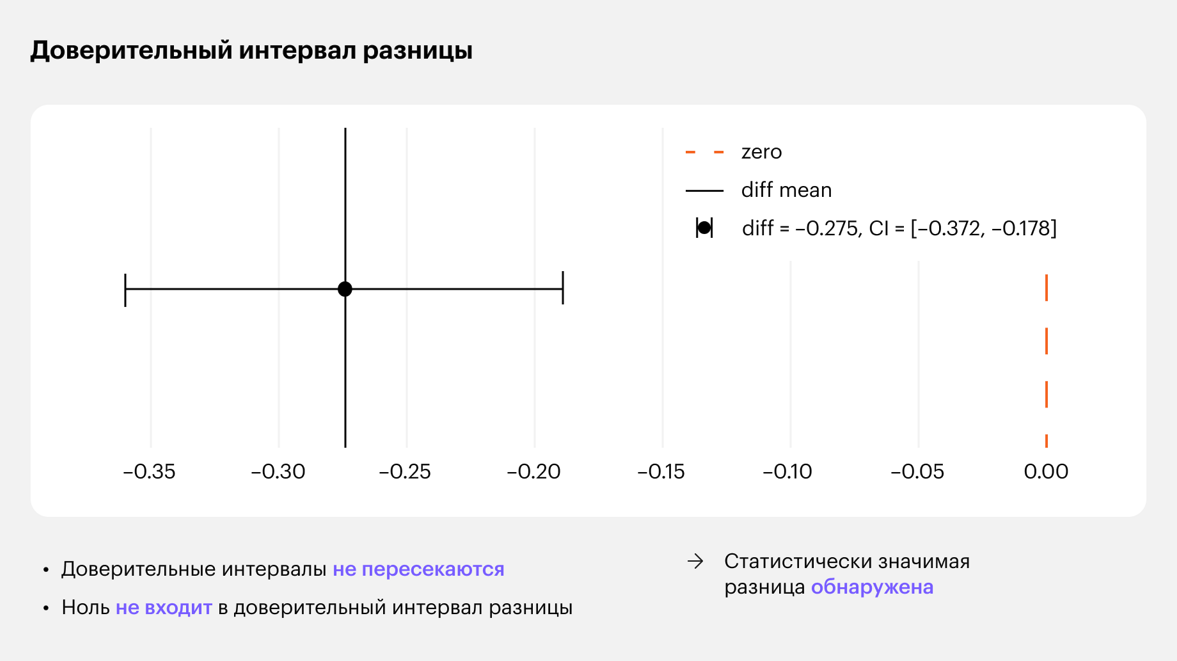

### Вывод

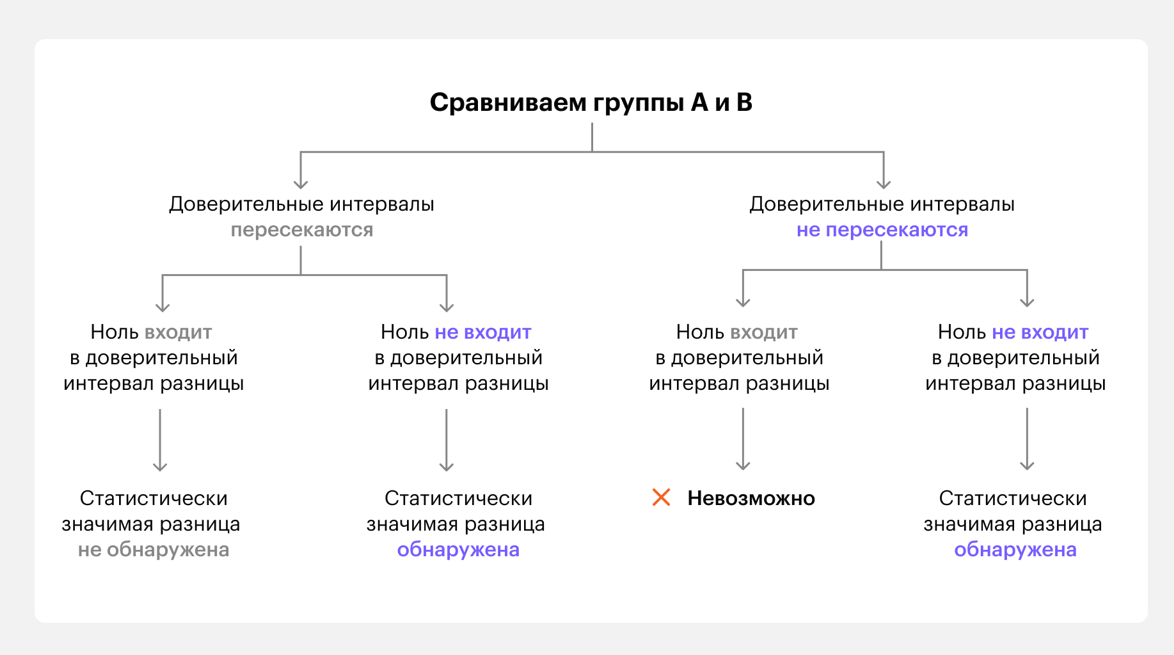

# Распределение хи-квадрат

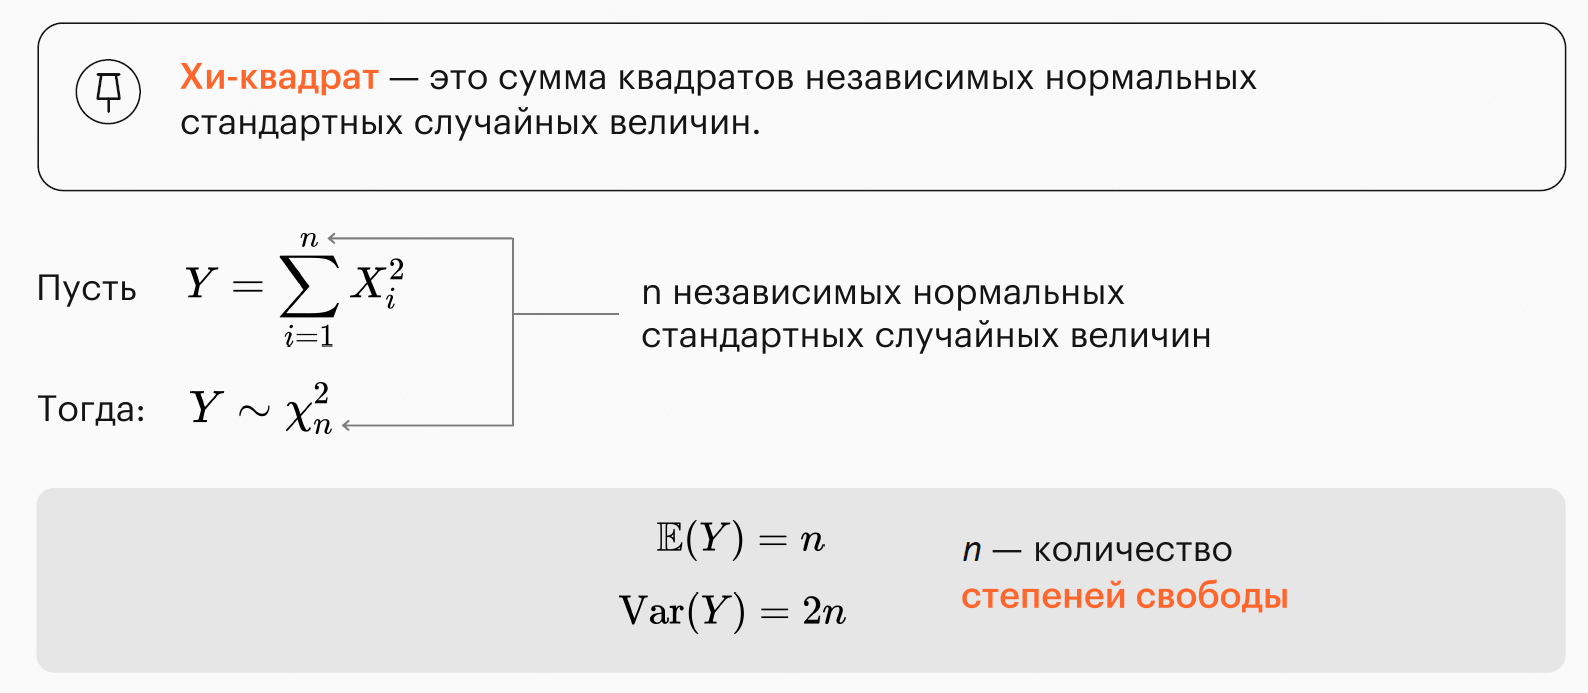

[Калькулятор распределений](https://gallery.shinyapps.io/dist_calc/).

In [ ]:
from scipy.stats import chi2

Зададим параметры для множественного отображения **функции плотности** и&nbsp;**функции распределения**.

In [ ]:
dfs = [3, 10, 30, 50]
x = np.linspace(0, 80, 1000)
colors = ['blue', 'green', 'red', 'purple']

Визуализируем **функцию плотности хи-квадрата**.

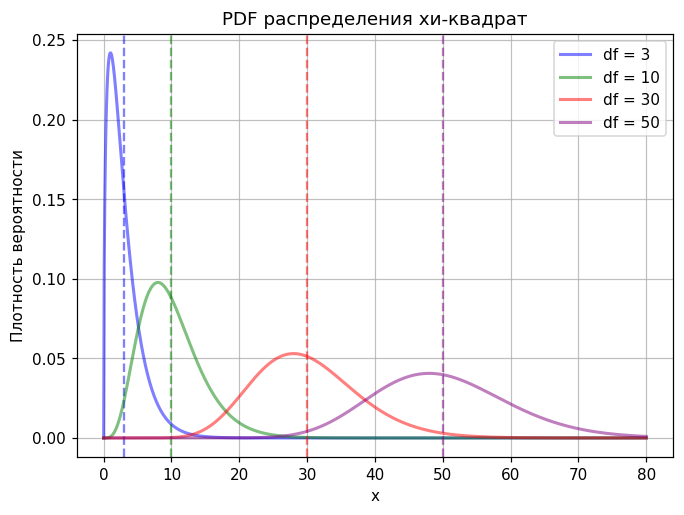

In [ ]:
# График PDF
plt.figure(figsize=(7, 5))
for i, df in enumerate(dfs):
    color = colors[i % len(colors)]
    plt.plot(x, chi2.pdf(x, df), label=f'df = {df}', linewidth=2, color=color, alpha=.5)

    # Вертикальная линия матожидания
    mean = df
    plt.axvline(x=mean, linestyle='--', color=color, alpha=0.5)

plt.title('PDF распределения хи-квадрат')
plt.xlabel('x')
plt.ylabel('Плотность вероятности')
plt.legend()
plt.show()

Визуализируем **функцию распределения хи-квадрата**.

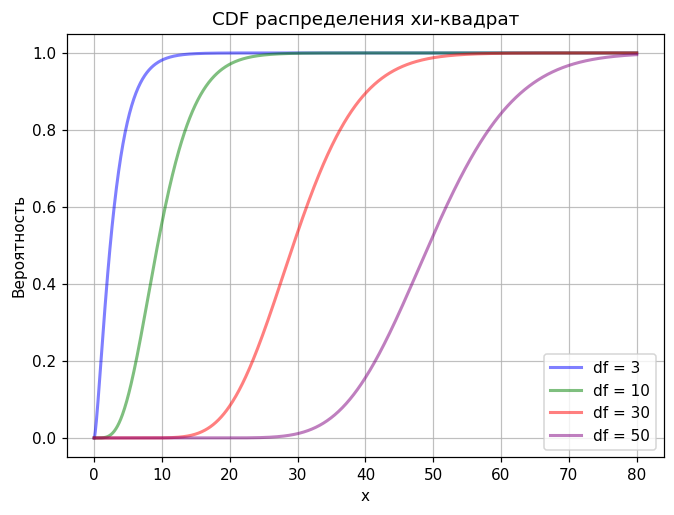

In [ ]:
# График CDF
plt.figure(figsize=(7,5))
for i, df in enumerate(dfs):
    color = colors[i % len(colors)]
    plt.plot(x, chi2.cdf(x, df), label=f'df = {df}', linewidth=2, color=color, alpha=.5)

plt.title('CDF распределения хи-квадрат')
plt.xlabel('x')
plt.ylabel('Вероятность')
plt.legend()
plt.show()

# Доверительный интервал для дисперсии

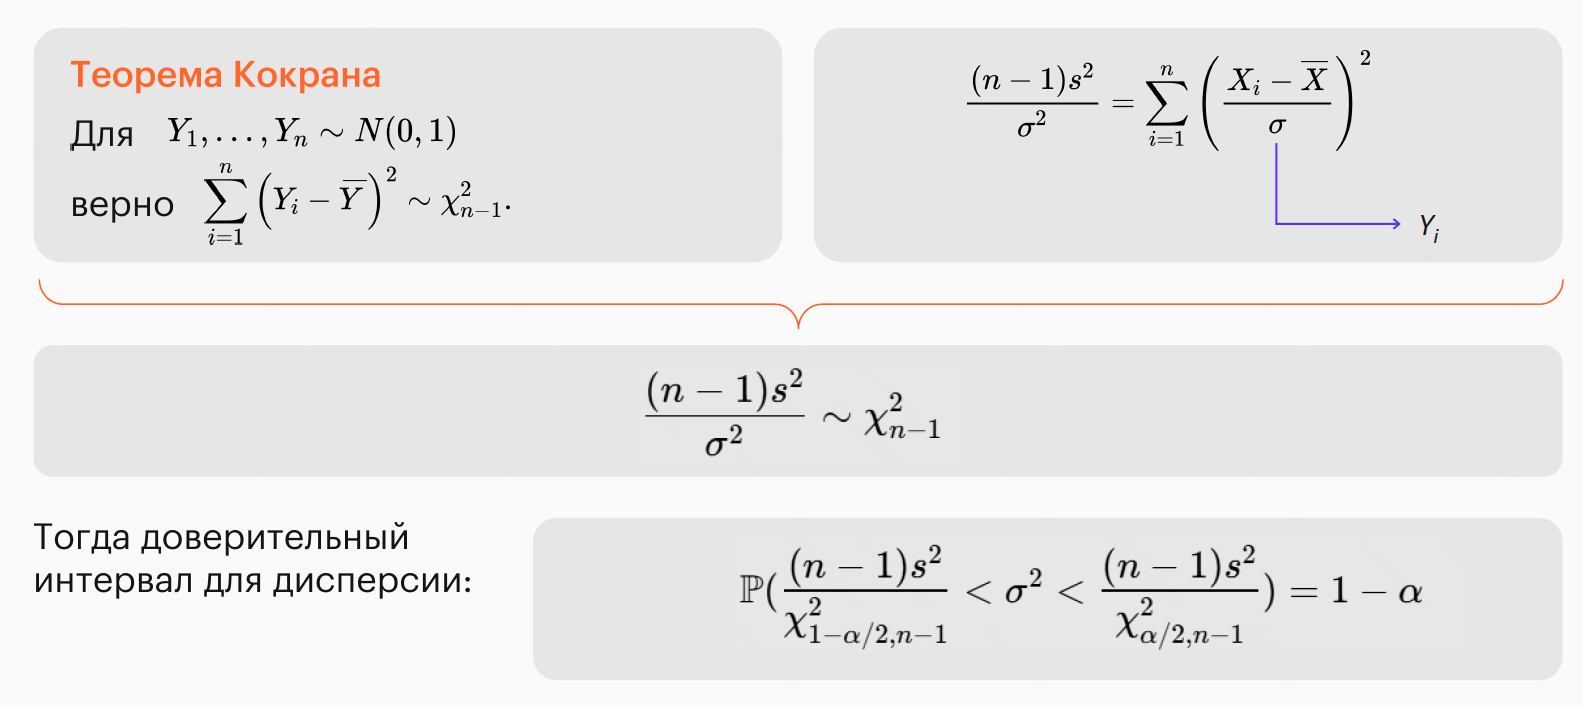



Для нормально распределённой выборки доверительный интервал дисперсии вычисляется по&nbsp;формуле

$$
CI_{1-\alpha}(\sigma^2) = \left[ \frac{(n-1)s^2}{\chi^2_{1-\alpha/2, n-1}}, \frac{(n-1)s^2}{\chi^2_{\alpha/2, n-1}} \right],
$$

где $s^2$&nbsp;— выборочная дисперсия, $\chi^2_{\alpha, n-1}$&nbsp;— квантиль распределения хи-квадрат с&nbsp;$n-1$ степенями свободы, $n$&nbsp;— размер выборки.

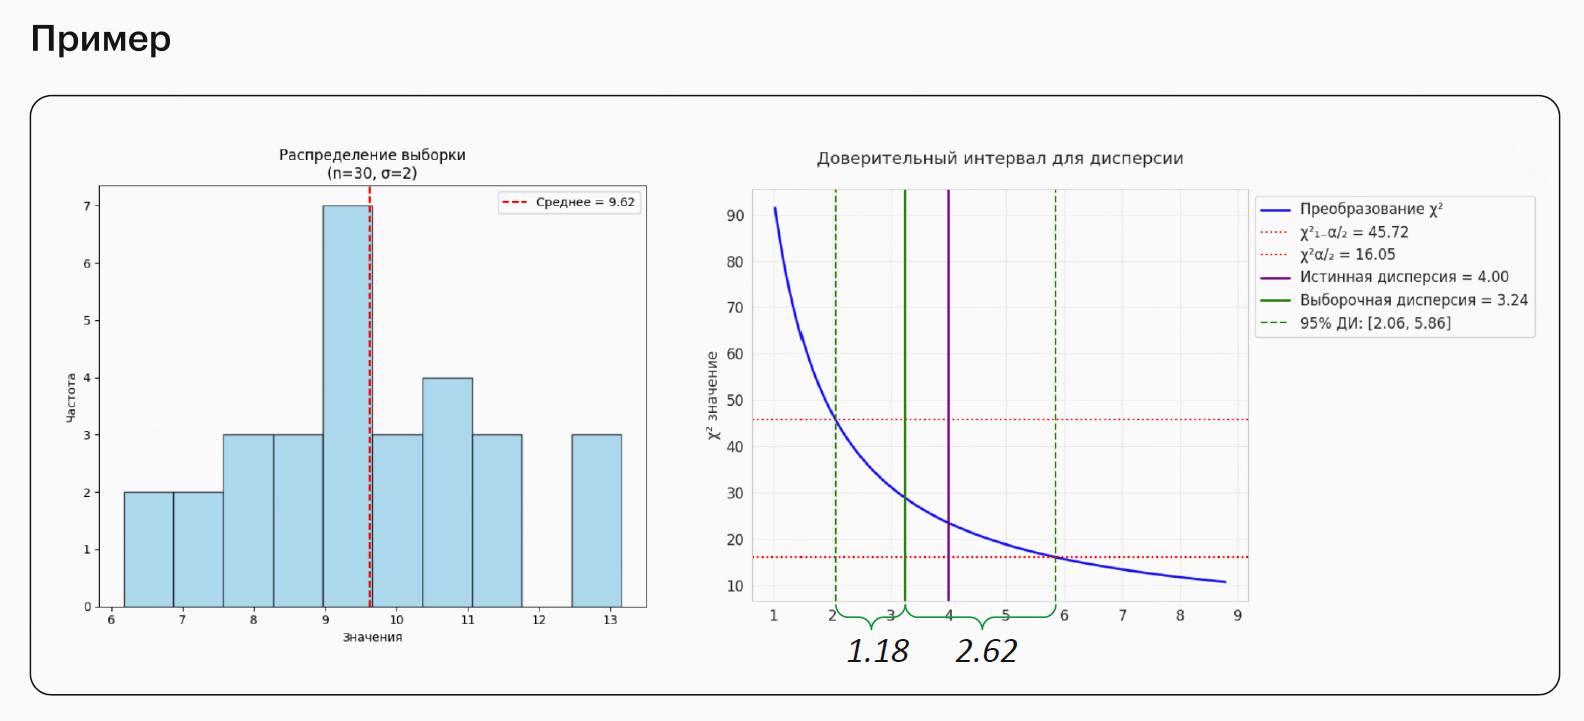

# Симуляции и численные методы

## Монте-Карло

**Метод Монте-Карло** — это способ приближённо вычислять величины с помощью большого числа случайных симуляций.

Схема обычно такая:

1. задаём случайный механизм;
2. много раз генерируем случайный результат;
3. для каждого результата считаем интересующую величину;
4. усредняем результаты или смотрим их распределение.

Например, вероятность события можно оценить долей симуляций, в которых оно произошло:

$$
\mathbb{P}(A)
\approx
\frac{1}{B}\sum_{b=1}^B \mathbf{1}\{A_b\}.
$$

Чем больше симуляций, тем меньше случайный шум самой оценки Монте-Карло.

### Пример 1. Среднее время просмотра

Какова вероятность, что среднее время просмотра окажется большим $220$ секунд?

Предположим, что время просмотра распределено нормально с параметрами $\mu=210$ и $\sigma=60$.

In [ ]:
B = 10_000
n = 30

samples = rng.normal(loc=210, scale=60, size=(B, n))
sample_means = samples.mean(axis=1)

prob = (sample_means > 220).mean()

print(f"P(X̄ > 220) ≈ {prob:.3f}")

P(X̄ > 220) ≈ 0.179


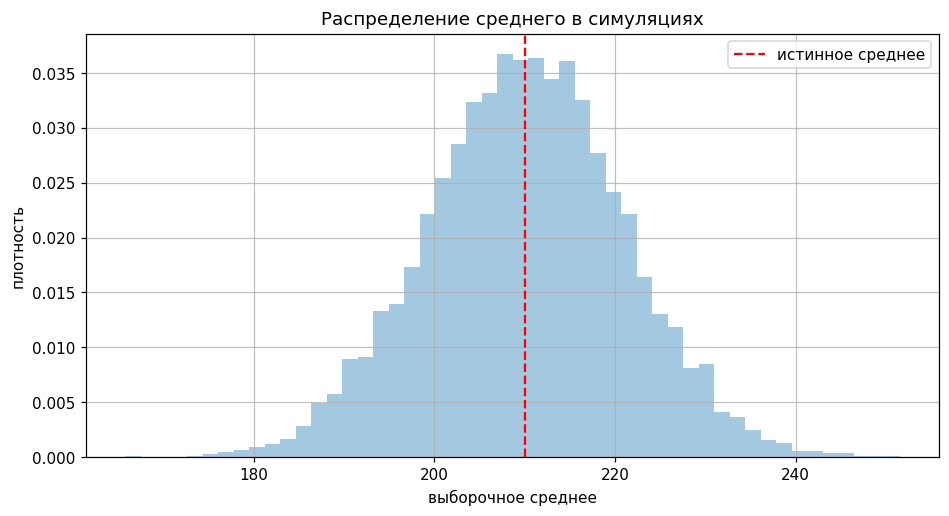

In [ ]:
plt.hist(sample_means, bins=50, density=True, alpha=0.4)
plt.axvline(210, linestyle="--", label="истинное среднее", color='red')
plt.xlabel("выборочное среднее")
plt.ylabel("плотность")
plt.title("Распределение среднего в симуляциях")
plt.legend()

plt.show()

**Сравним с точным расчётом**

В этом примере аналитическое решение известно.

Если

$$
X\sim\mathcal N(210,60^2),
$$

то для выборки размера $n=30$

$$
\overline X\sim
\mathcal N\left(
210,\frac{60^2}{30}
\right).
$$

Поэтому

$$
\mathbb{P}(\overline X>220)
=
1-\Phi\left(
\frac{220-210}{60/\sqrt{30}}
\right)
\approx 0.181.
$$

Результат Монте-Карло должен получиться близким к этому значению.

Здесь точный ответ известен, поэтому пример позволяет проверить работу метода.
На практике Монте-Карло особенно полезен тогда, когда аналогичную вероятность
или математическое ожидание аналитически посчитать трудно.

### Пример 2. Оценка числа $\pi$ по площади круга

Сгенерируем точки в единичном квадрате и посчитаем долю точек, для которых
$x^2 + y^2 \le 1$. Они лежат внутри четверти единичного круга. Её площадь
равна $\pi/4$, поэтому оценка числа $\pi$ равна четырём долям попаданий.

Здесь используется общий приём: вероятность события можно оценить средним
индикатора события. В numpy значения `True` и `False` усредняются как единицы
и нули.

In [ ]:
N=10000

In [ ]:
x = rng.uniform(0, 1, N)
y = rng.uniform(0, 1, N)
inside = x**2 + y**2 <= 1.0
print(f"оценка: {4 * inside.mean():.4f}, точное значение: {np.pi:.4f}")

оценка: 3.1392, точное значение: 3.1416


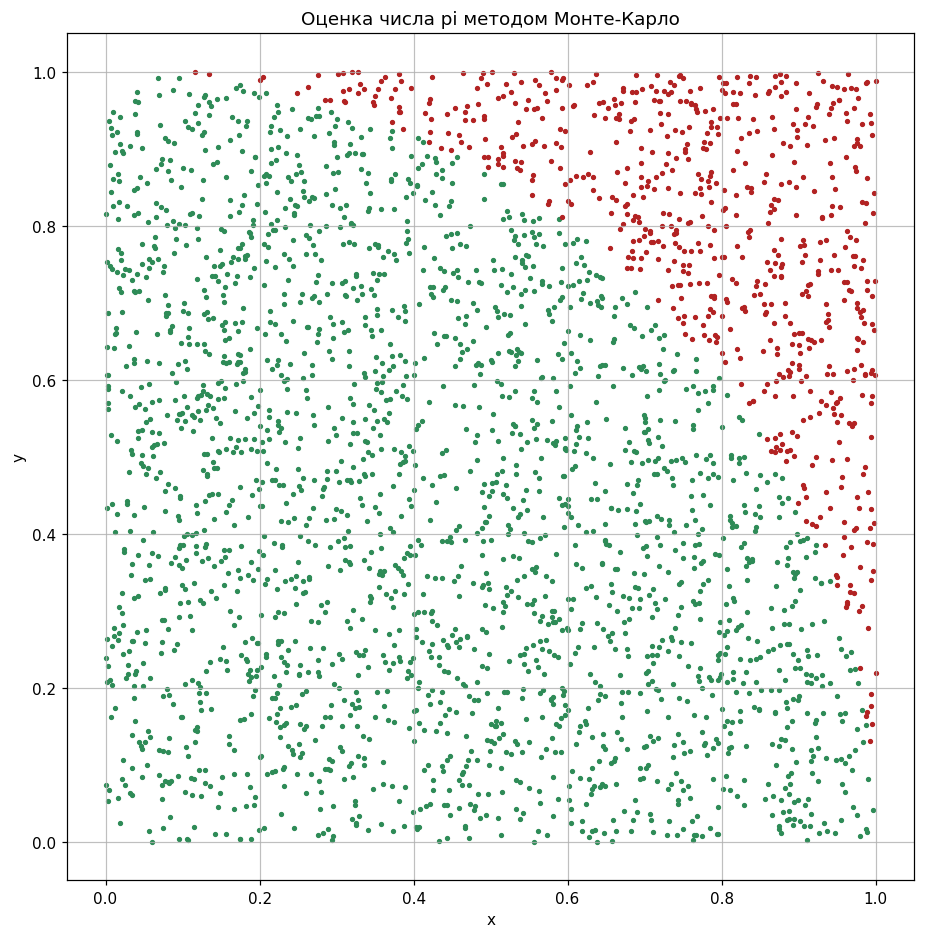

In [ ]:
k = 3000
plt.figure(figsize=(10, 10))
plt.scatter(x[:k][inside[:k]], y[:k][inside[:k]], s=6, color="seagreen")
plt.scatter(x[:k][~inside[:k]], y[:k][~inside[:k]], s=6, color="firebrick")
plt.gca().set_aspect("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Оценка числа pi методом Монте-Карло")
plt.show()

В обоих примерах искомая величина записана как среднее по случайным исходам.
Такой же подход применим к продуктовой модели, если для одного сценария
результат вычислить легко.

### Сколько нужно симуляций?

Результат Монте-Карло сам является случайной величиной.

Например, для оценки вероятности

$$
\hat p =
\frac{1}{B}\sum_{b=1}^{B} I_b
$$

стандартная ошибка Монте-Карло приблизительно равна

$$
SE_{MC}
\approx
\sqrt{\frac{\hat p(1-\hat p)}{B}}.
$$

Она уменьшается как

$$
\frac{1}{\sqrt B}.
$$

Поэтому увеличение числа симуляций в $100$ раз уменьшает случайную ошибку
Монте-Карло примерно только в $10$ раз.

Число симуляций $B$ отвечает за **точность численного расчёта**, а не за
количество информации в исходных данных.

## Бутстреп

**А если распределение данных неизвестно?**

Ранее мы могли генерировать новые выборки, потому что **знали распределение генеральной совокупности**.

В реальной задаче обычно есть только одна наблюдаемая выборка, а распределение данных неизвестно.

Здесь возникает идея бутстрепа:

- в Монте-Карло мы генерируем данные из **заданной модели**;
- в бутстрепе вместо неизвестной генеральной совокупности используем **наблюдаемую выборку**;
- много раз берём из неё новые выборки **с возвращением**.

Таким образом, бутстреп использует ту же идею многократной случайной симуляции, но не требует заранее знать распределение данных.




[Статья от нашего автора Павела Мосина](https://medium.com/@pavel.mos96/bootstrap-%D1%88%D0%B2%D0%B5%D0%B9%D1%86%D0%B0%D1%80%D1%81%D0%BA%D0%B8%D0%B9-%D0%BD%D0%BE%D0%B6-%D0%B0%D0%BD%D0%B0%D0%BB%D0%B8%D1%82%D0%B8%D0%BA%D0%B0-aa8c185943e5)

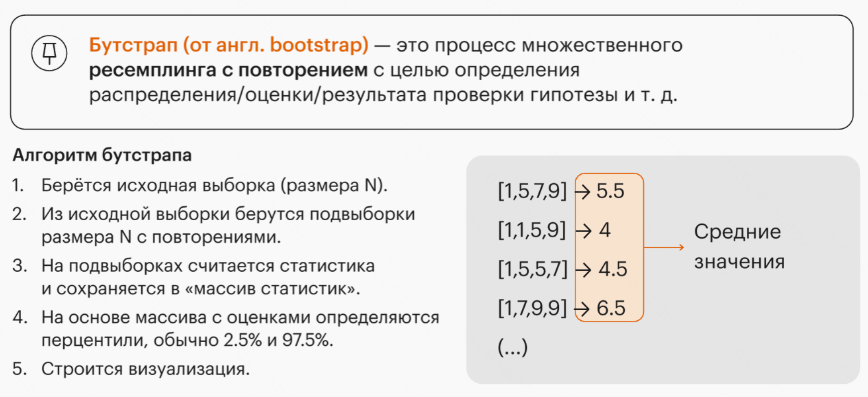

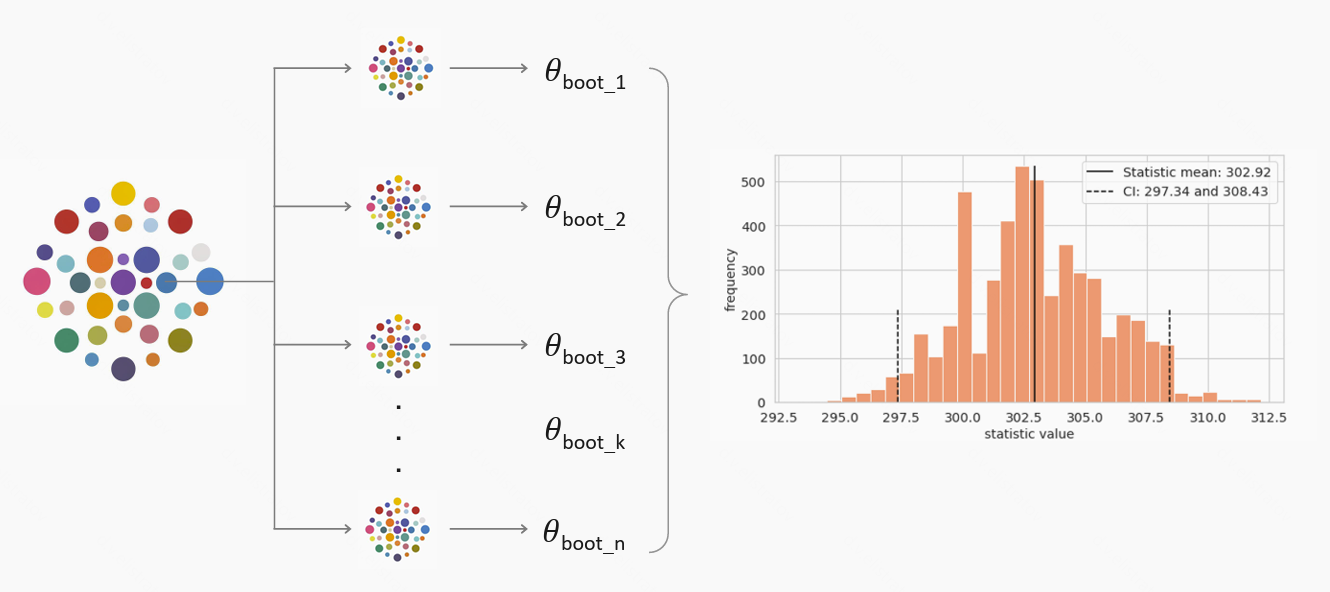

### Пример 1. Доверительный интервал для среднего

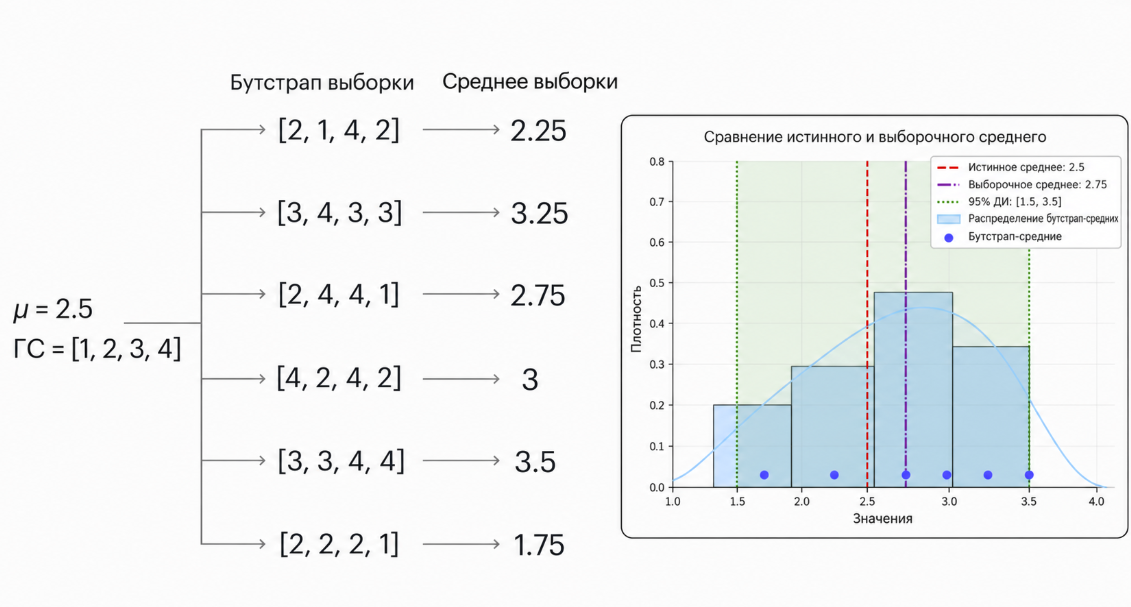

### Пример 2. Доверительный интервал для доли

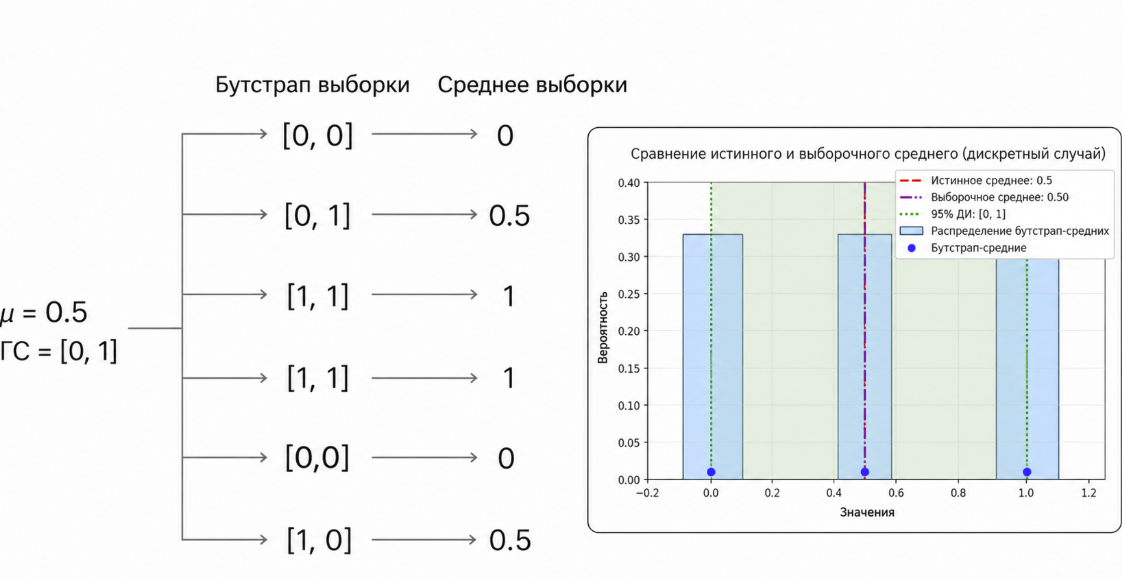

### Пример 3. Доверительный интервал для дисперсии

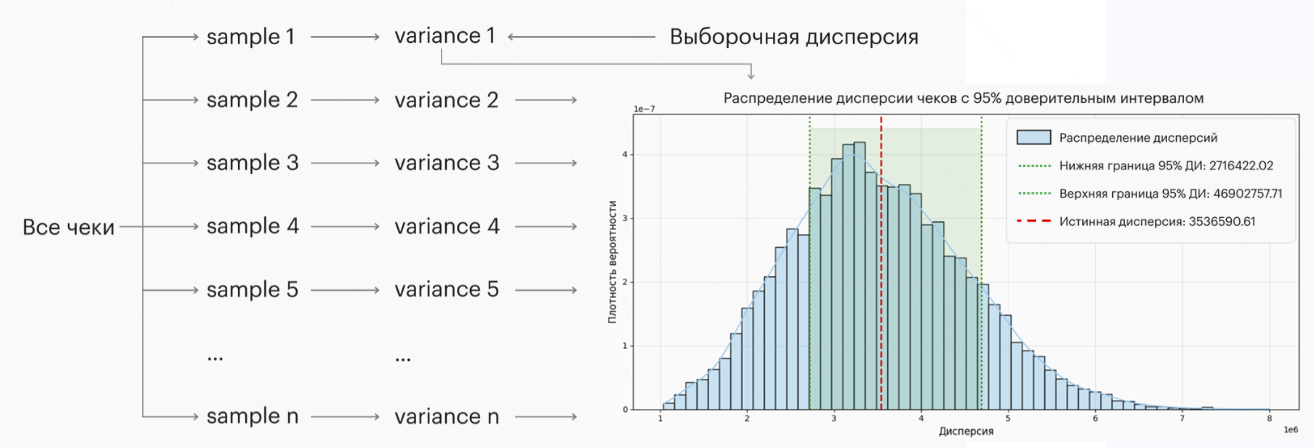

### Пример 4. Доверительный интервал для квантилей равномерного распределения

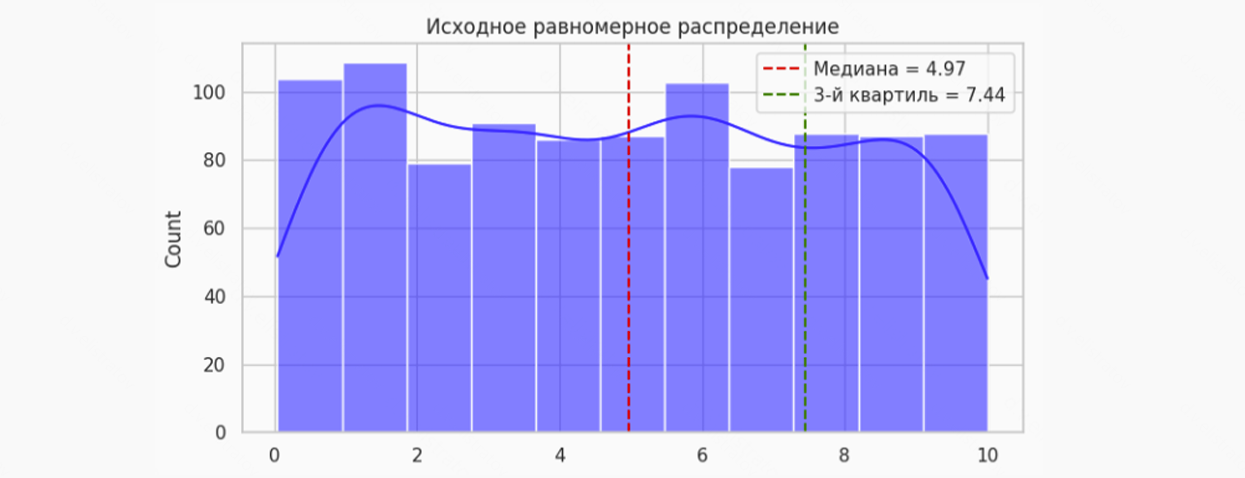

**Оценим границы доверительного интервала медианы для маленькой и большой выборок**

1. Из исходной выборки размера $N$ извлекается $n$ бутстреп-выборок (обычно $n \geq 1000$) того&nbsp;же размера $N$ с&nbsp;возвращением.

2. Для каждой выборки вычисляется медиана:

$$
\text{median}_i = \text{median}(\{x_1^*, x_2^*, ..., x_n^*\}), \quad i = 1,...,n.
$$

3. Доверительный интервал вычисляется как квантили распределения бутстреп-медиан:

$$
CI_{1-\alpha} = \left[Q_{\alpha/2}(\{\text{median}_b\}), Q_{1-\alpha/2}(\{\text{median}_b\})\right],
$$

где $Q_p$ — $p$-квантиль распределения.

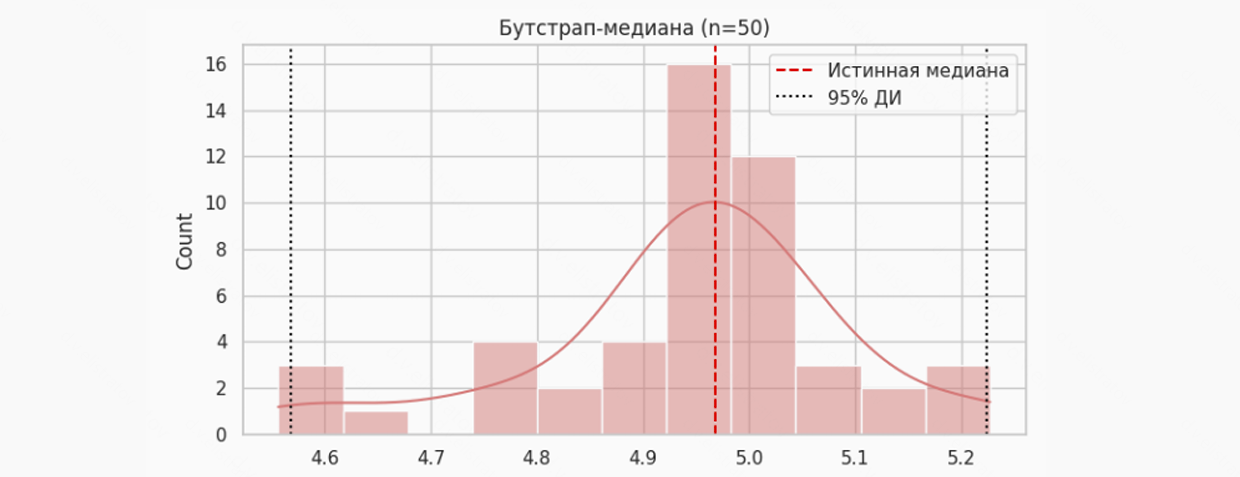

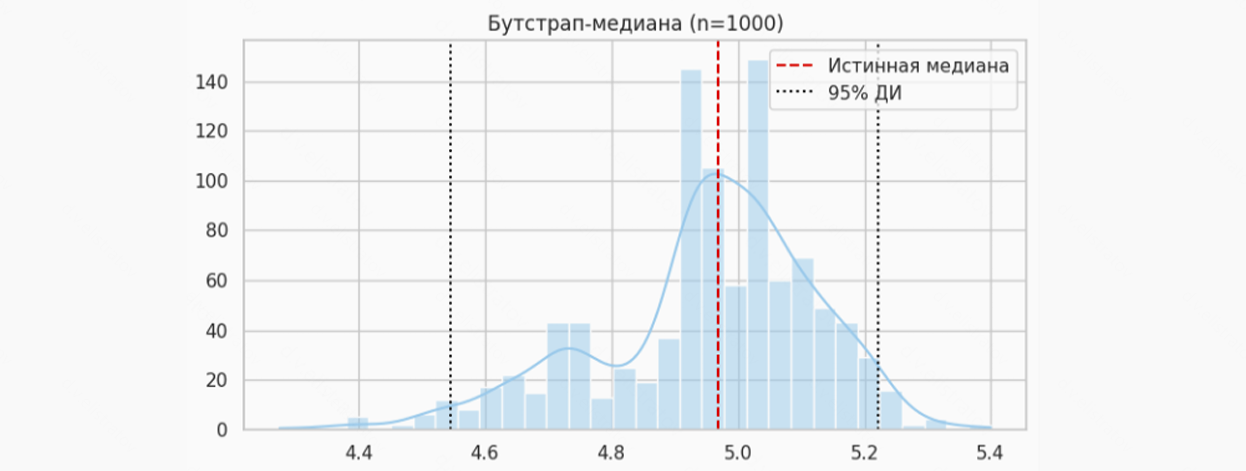

**Оценим границы доверительного интервала третьего квартиля для маленькой и большой выборок**

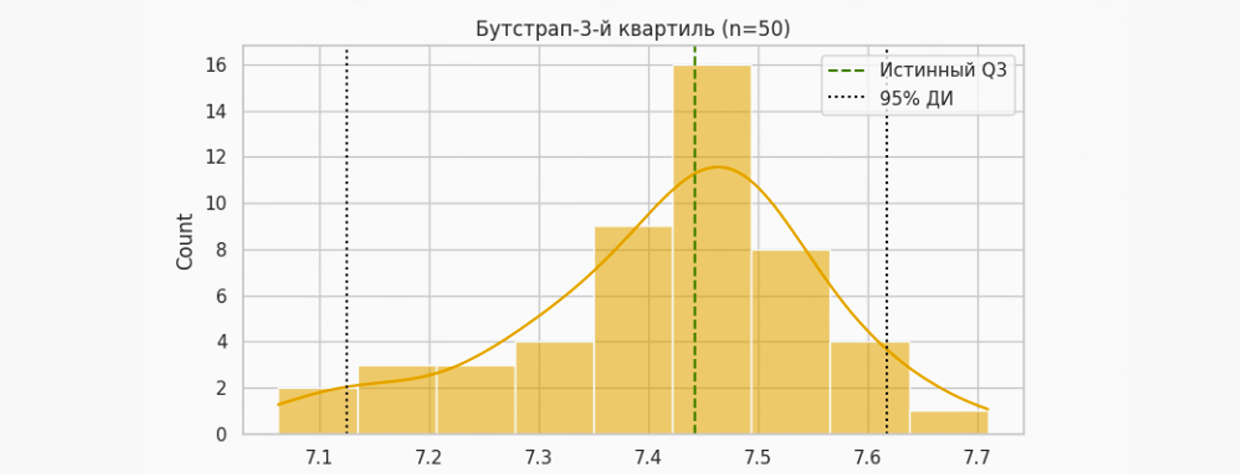

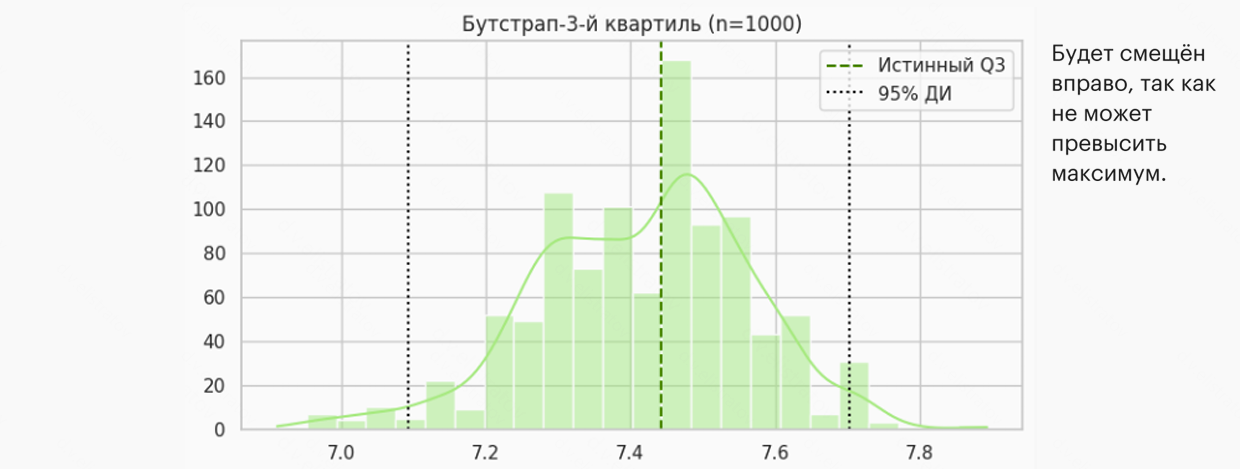

### Ограничения бутстрапа

Бутстрап не является методом «без предположений».

Обычный непараметрический бутстрап предполагает, что исходная выборка
достаточно хорошо представляет генеральную совокупность, а схема
ресэмплирования соответствует способу получения данных.

Если исходная выборка мала или нерепрезентативна, многократное
ресэмплирование не создаёт отсутствующую информацию.

Особенно осторожно обычный бутстрап нужно применять к зависимым наблюдениям,
например временным рядам: случайное перемешивание отдельных наблюдений может
разрушить зависимость между ними.

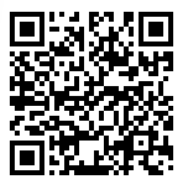